# Crowd AI Project — v4: Detection → Tracking → Trajectories (MOT20)

**What changed from project1.ipynb**
- **Honest evaluation:** train on MOT20-01/02/03. MOT20-05 frames 1–1657 = **VAL** (choose models, tune trackers). Frames 1658–3315 = **TEST** (used once, for final numbers).
- **Detection:** fixed box clipping, imgsz 1280, longer training, YOLOv8 **n / s / m** + YOLO11n (PDF Experiment 1).
- **Real FPS / latency:** batch-1, end-to-end timing.
- **Tracking:** wider ByteTrack tuning on VAL, **DeepSORT** comparison (PDF Experiment 2), official **TrackEval** scores (HOTA / MOTA / IDF1) on TEST.
- **Trajectories:** CSV with centre **and foot point**, plus tracking and trajectory videos.

- **Stage 4 — Zones (cells 15–22):** per-zone, per-second crowd statistics, accuracy against the ground truth, figures and a zone video.

**How to run:** use **Runtime → Run all**. It is safe: every expensive step first checks Drive and, if its results are already saved, **loads them instead of recomputing**. Training, tuning, evaluation, videos and figures are never repeated by accident.
- To redo one step on purpose, add its name to `FORCE` in CONFIG, e.g. `FORCE = {"bytetrack"}`.
- Once everything is saved, no GPU is needed (all GPU steps are skipped). A GPU is only needed for steps that still have to run (training, detector comparison, FPS, detection cache).
- If a long GPU step is interrupted, run all again: training resumes from `last.pt`, and finished steps are skipped.

All outputs go to `MyDrive/Crowd_AI_Project/runs_v4/` (zones: `runs_v4/zones/`); your old `runs/` folder is not touched.

In [6]:
# ============================================================
# CELL 0 — CONFIG  (run first, every session)
# ============================================================

import os, json, time, shutil, zipfile, subprocess
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount("/content/drive")

# ---------- Google Drive ----------
PROJECT_DRIVE  = "/content/drive/MyDrive/Crowd_AI_Project"
DATASETS_DRIVE = f"{PROJECT_DRIVE}/datasets"
RUNS_DRIVE     = f"{PROJECT_DRIVE}/runs_v4"          # new folder, old runs untouched
os.makedirs(RUNS_DRIVE, exist_ok=True)

MOT20_ZIP_DRIVE = "/content/drive/MyDrive/MOT20.zip"
LABELS_ZIP_DRIVE = "/content/drive/MyDrive/MOT20Labels.zip"

# ---------- Local Colab paths ----------
MOT20_EXTRACT  = "/content/MOT20"
LABELS_EXTRACT = "/content/MOT20Labels"
YOLO_ROOT      = "/content/MOT20_YOLO_v4"
DATA_YAML      = f"{YOLO_ROOT}/data.yaml"
TE_ROOT        = "/content/trackeval_work"           # TrackEval input/output files

# ---------- Split ----------
# Only MOT20-01/02/03/05 have ground truth (04/06/07/08 are unlabeled test sequences).
TRAIN_SEQUENCES = ["MOT20-01", "MOT20-02", "MOT20-03"]
EVAL_SEQUENCE   = "MOT20-05"
SPLIT_FRAME     = 1657      # VAL = frames 1..1657 | TEST = frames 1658..3315
FPS             = 25        # MOT20 frame rate

# ---------- Detection ----------
DETECTORS      = ["yolov8n", "yolov8s", "yolov8m", "yolo11n"]
IMG_SIZE       = 1280       # MOT20 people are tiny; 512 was too small
EPOCHS         = 50
PATIENCE       = 15
BATCH          = -1         # auto batch size (~60% of GPU memory)
SEED           = 42
MAX_DET        = 1000       # MOT20 frames have up to ~220 people
MIN_VISIBILITY = 0.0        # 0.0 = keep every annotated pedestrian (MOT standard)
MIN_BOX_PX     = 2          # drop boxes smaller than this after clipping

# None = automatically use the detector with the best VAL mAP50-95.
# Set e.g. "yolov8s" to force a faster/slower model for tracking.
TRACK_DETECTOR = None

# ---------- Output files on Drive ----------
DET_COMPARE_CSV = f"{RUNS_DRIVE}/detector_comparison.csv"
FPS_CSV         = f"{RUNS_DRIVE}/detector_fps.csv"
SELECTION_JSON  = f"{RUNS_DRIVE}/selection.json"
BYTE_GRID_CSV   = f"{RUNS_DRIVE}/bytetrack_tuning_VAL.csv"
DEEP_GRID_CSV   = f"{RUNS_DRIVE}/deepsort_tuning_VAL.csv"
FINAL_CSV       = f"{RUNS_DRIVE}/tracking_TEST_trackeval.csv"
TRAJ_CSV        = f"{RUNS_DRIVE}/trajectories_MOT20-05.csv"
TRACK_VIDEO     = f"{RUNS_DRIVE}/tracking_MOT20-05.mp4"
TRAJ_VIDEO      = f"{RUNS_DRIVE}/trajectories_MOT20-05.mp4"
DIFFICULTY_CSV  = f"{RUNS_DRIVE}/MOT20_difficulty_analysis.csv"
REPORT_ZIP      = f"{RUNS_DRIVE}/report_figures.zip"

# ---------- Zones (stage 4) ----------
ZONES_DIR   = f"{RUNS_DRIVE}/zones"
FIG_DIR     = f"{ZONES_DIR}/figures"
ZONES_VIDEO = f"{ZONES_DIR}/zones_{EVAL_SEQUENCE}.mp4"
ZONES_ZIP   = f"{ZONES_DIR}/zones_figures.zip"
os.makedirs(FIG_DIR, exist_ok=True)
GRID_ROWS, GRID_COLS = 3, 4             # 12 zones
CUSTOM_ZONES = None                     # optional: {"Gate A": [[x, y], ...], ...} polygons in pixels
STEP       = 25                         # 1 second per step
MIN_RUN    = 5                          # zone visits shorter than 5 frames (0.2 s) are border jitter
SPEED_LAG  = 5                          # speed from foot displacement over 5 frames (0.2 s)
GT_MIN_VIS = 0.25                       # second reference: GT people at least 25% visible

# Crowding levels — all thresholds are LEARNED ON THE VAL HALF ONLY (frames 1..SPLIT_FRAME),
# then applied unchanged to TEST, so later prediction results stay honest.
#   "own"   level: compares a zone with its OWN history.
#           LOW <= zone's median count < MEDIUM < zone's 90th percentile <= HIGH
#   "floor" level: physical crowding, comparable BETWEEN zones.
#           floor coverage = people x typical person size in that zone / zone area
#           (far-away people look smaller, so this corrects for camera perspective);
#           LOW / HIGH cut-offs = median / 90th percentile of coverage pooled over ALL zones.
LEVEL_Q     = (0.50, 0.90)
VIDEO_LEVEL = "floor"                   # which level colours the zone video: "floor" or "own"

def level3(x, lo, hi):
    """LOW if x <= lo, HIGH if x >= hi, else MEDIUM (works on numbers and arrays)."""
    return np.where(np.asarray(x) >= hi, "HIGH", np.where(np.asarray(x) <= lo, "LOW", "MEDIUM"))

GT_COLS = ["frame", "id", "x", "y", "w", "h", "mark", "cls", "vis"]

# ---------- Skip finished work ----------
# Every expensive step checks Drive first: if its results are saved, they are loaded instead of
# recomputed, so "Run all" is safe. To redo a step on purpose, add its name here, e.g. {"bytetrack"}.
# Names: convert, compare, fps, difficulty, bytetrack, deepsort, final, trajectories,
#        report_figures, zones_figures, zones_video
FORCE = {"zones_figures", "zones_video"}


def saved(step, *paths):
    """True when the step's results exist on Drive and the step is not in FORCE."""
    if step not in FORCE and all(os.path.exists(p) for p in paths):
        print(f"✓ '{step}' already done — loaded saved results (add '{step}' to FORCE to recompute)")
        return True
    return False


# ============================================================
# Helpers used by every later cell
# ============================================================

def run_name(model_name):
    return f"{model_name}_MOT20_{IMG_SIZE}"

def best_weights(model_name):
    return f"{RUNS_DRIVE}/{run_name(model_name)}/weights/best.pt"

_seq_dir_cache = {}

def find_seq_dir(seq):
    """Return .../<seq>/img1 inside the extracted MOT20 folder."""
    if seq not in _seq_dir_cache:
        for root, dirs, files in os.walk(MOT20_EXTRACT):
            if os.path.basename(root) == "img1" and os.path.basename(os.path.dirname(root)) == seq:
                _seq_dir_cache[seq] = root
                break
        else:
            raise FileNotFoundError(f"{seq}/img1 not found under {MOT20_EXTRACT} — run SETUP first")
    return _seq_dir_cache[seq]

def find_gt(seq):
    for root, dirs, files in os.walk(LABELS_EXTRACT):
        if os.path.basename(root) == "gt" and os.path.basename(os.path.dirname(root)) == seq:
            path = os.path.join(root, "gt.txt")
            if os.path.isfile(path):
                return path
    raise FileNotFoundError(f"gt.txt for {seq} not found under {LABELS_EXTRACT}")

def list_frames(img_dir):
    return sorted(f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png")))

def load_gt(seq):
    """All MOT20 annotations (all classes). Columns: GT_COLS."""
    return pd.read_csv(find_gt(seq), header=None, names=GT_COLS)

def pedestrians(gt):
    """Valid pedestrians only: mark == 1 and class == 1."""
    return gt[(gt["mark"] == 1) & (gt["cls"] == 1)]

def split_range(split):
    """(first_frame, last_frame) of MOT20-05 for 'val', 'test' or 'full'."""
    n = len(list_frames(find_seq_dir(EVAL_SEQUENCE)))
    return {"val": (1, SPLIT_FRAME), "test": (SPLIT_FRAME + 1, n), "full": (1, n)}[split]

def get_track_detector():
    if TRACK_DETECTOR:
        return TRACK_DETECTOR
    if os.path.isfile(SELECTION_JSON):
        with open(SELECTION_JSON) as f:
            return json.load(f)["track_detector"]
    raise RuntimeError("No detector selected yet — run the DETECTOR COMPARISON cell first")

def all_detectors_done():
    return all(os.path.isfile(f"{RUNS_DRIVE}/{run_name(d)}/DONE") for d in DETECTORS)

# The YOLO-format dataset (cells 2-3) is only needed to train or compare detectors
NEED_YOLO_DATASET = (not all_detectors_done() or not os.path.isfile(DET_COMPARE_CSV)
                     or bool({"convert", "compare"} & FORCE))

print("✓ Config loaded")
print("Runs folder:", RUNS_DRIVE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Config loaded
Runs folder: /content/drive/MyDrive/Crowd_AI_Project/runs_v4


In [7]:
# ============================================================
# CELL 1 — SETUP: install, copy and extract MOT20, get TrackEval
# ============================================================

!pip install -q ultralytics deep-sort-realtime

import ultralytics, torch
print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "none (fine if every GPU step is already saved; otherwise enable a GPU)")

# ---------- Copy zips Drive → local (much faster to read) ----------
for src in [MOT20_ZIP_DRIVE, LABELS_ZIP_DRIVE]:
    if not os.path.isfile(src):
        raise FileNotFoundError(src)
    dst = f"/content/{os.path.basename(src)}"
    if not os.path.isfile(dst) or os.path.getsize(dst) != os.path.getsize(src):
        print(f"Copying {os.path.basename(src)} ({os.path.getsize(src) / 1024**3:.2f} GB)...")
        shutil.copy2(src, dst)

# ---------- Extract (a marker file makes interrupted extractions re-run) ----------
for zip_path, out_dir in [("/content/MOT20.zip", MOT20_EXTRACT),
                          ("/content/MOT20Labels.zip", LABELS_EXTRACT)]:
    marker = f"{out_dir}/.extracted"
    if not os.path.isfile(marker):
        print(f"Extracting {os.path.basename(zip_path)}...")
        shutil.rmtree(out_dir, ignore_errors=True)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(out_dir)
        open(marker, "w").close()
print("✓ MOT20 ready")

# ---------- TrackEval (official MOTChallenge evaluation code) ----------
if not os.path.isdir("/content/TrackEval"):
    subprocess.run(["git", "clone", "-q", "https://github.com/JonathonLuiten/TrackEval.git",
                    "/content/TrackEval"], check=True)
print("✓ TrackEval ready")

# ---------- Show sequences ----------
for seq in TRAIN_SEQUENCES + [EVAL_SEQUENCE]:
    print(f"{seq}: {len(list_frames(find_seq_dir(seq)))} frames | GT: {find_gt(seq)}")
print("VAL  frames:", split_range("val"))
print("TEST frames:", split_range("test"))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 143.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.182
GPU: NVIDIA A100-SXM4-80GB
Copying MOT20.zip (4.68 GB)...
Copying MOT20Labels.zip (0.02 GB)...
Extracting MOT20.zip...
Extracting MOT20Labels.zip...
✓ MOT20 ready
✓ TrackEval ready
MOT20-01: 429 frames | GT: /content/MOT20Labels/MOT20Labels/train/MOT20-01/gt/gt.txt
MOT20-02: 2782 frames | GT: /content/MOT20Labels/MOT20Labels/train/MOT20-02/gt/gt.txt
MOT20-03: 2405 frame

In [5]:
# ============================================================
# CELL 2 — CONVERT MOT20 → YOLO  (train / val / test)
# FIX: boxes are clipped by their corners (x1,y1,x2,y2), then normalised.
# ============================================================

from collections import defaultdict
from PIL import Image

if not NEED_YOLO_DATASET:
    print("✓ Skipped: all detectors are trained and compared, so the YOLO dataset is not needed (add 'convert' to FORCE to rebuild it)")
else:
    shutil.rmtree(YOLO_ROOT, ignore_errors=True)        # no stale files / label caches
    for split in ["train", "val", "test"]:
        os.makedirs(f"{YOLO_ROOT}/images/{split}", exist_ok=True)
        os.makedirs(f"{YOLO_ROOT}/labels/{split}", exist_ok=True)


    def convert(seq, split, first_frame, last_frame):
        img_dir = find_seq_dir(seq)
        frames = list_frames(img_dir)
        with Image.open(os.path.join(img_dir, frames[0])) as im:
            W, H = im.size

        gt = pedestrians(load_gt(seq))
        gt = gt[(gt["vis"] >= MIN_VISIBILITY) &
                (gt["frame"] >= first_frame) & (gt["frame"] <= last_frame)]

        labels = defaultdict(list)
        dropped = 0
        for fr, x, y, w, h in gt[["frame", "x", "y", "w", "h"]].itertuples(index=False):
            # Clip the CORNERS to the image, then convert
            x1, y1 = max(0.0, x), max(0.0, y)
            x2, y2 = min(float(W), x + w), min(float(H), y + h)
            bw, bh = x2 - x1, y2 - y1
            if bw < MIN_BOX_PX or bh < MIN_BOX_PX:
                dropped += 1
                continue
            labels[int(fr)].append(
                f"0 {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {bw / W:.6f} {bh / H:.6f}")

        n_images = n_boxes = 0
        for name in frames:
            fr = int(os.path.splitext(name)[0])
            if not first_frame <= fr <= last_frame:
                continue
            new_name = f"{seq}_{name}"
            src = os.path.join(img_dir, name)
            dst = f"{YOLO_ROOT}/images/{split}/{new_name}"
            try:
                os.link(src, dst)                # hard link: instant, no extra disk space
            except OSError:
                shutil.copy2(src, dst)
            with open(f"{YOLO_ROOT}/labels/{split}/{os.path.splitext(new_name)[0]}.txt", "w") as f:
                if labels[fr]:
                    f.write("\n".join(labels[fr]) + "\n")
            n_images += 1
            n_boxes += len(labels[fr])

        print(f"{seq} [{first_frame}-{last_frame}] → {split:5s} | {W}x{H} | "
              f"images {n_images} | boxes {n_boxes} | dropped (too small after clipping) {dropped}")


    for seq in TRAIN_SEQUENCES:
        convert(seq, "train", 1, len(list_frames(find_seq_dir(seq))))
    convert(EVAL_SEQUENCE, "val",  *split_range("val"))
    convert(EVAL_SEQUENCE, "test", *split_range("test"))

    with open(DATA_YAML, "w") as f:
        f.write(f"path: {YOLO_ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\n"
                "names:\n  0: person\n")

    print("\n✓ data.yaml:", DATA_YAML)

MOT20-01 [1-429] → train | 1920x1080 | images 429 | boxes 19870 | dropped (too small after clipping) 0
MOT20-02 [1-2782] → train | 1920x1080 | images 2782 | boxes 154742 | dropped (too small after clipping) 0
MOT20-03 [1-2405] → train | 1173x880 | images 2405 | boxes 313658 | dropped (too small after clipping) 0
MOT20-05 [1-1657] → val   | 1654x1080 | images 1657 | boxes 327068 | dropped (too small after clipping) 0
MOT20-05 [1658-3315] → test  | 1654x1080 | images 1658 | boxes 319276 | dropped (too small after clipping) 0

✓ data.yaml: /content/MOT20_YOLO_v4/data.yaml


In [6]:
# ============================================================
# CELL 3 — DATA LEAKAGE CHECK  (train / val / test)
# ============================================================

import hashlib, itertools

if not NEED_YOLO_DATASET:
    print("✓ Skipped: the leakage check is only needed when the training dataset is (re)built")
else:
    def files(split, kind):
        return set(os.listdir(f"{YOLO_ROOT}/{kind}/{split}"))

    def stem(names):
        return {os.path.splitext(n)[0] for n in names}

    def frame_no(name):
        return int(os.path.splitext(name.split("_")[1])[0])

    def sha(path):
        h = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1 << 20), b""):
                h.update(chunk)
        return h.hexdigest()

    problems = []
    images = {s: files(s, "images") for s in ["train", "val", "test"]}
    labels = {s: files(s, "labels") for s in ["train", "val", "test"]}

    # 1. Filename overlap between any two splits
    for a, b in itertools.combinations(images, 2):
        n = len(images[a] & images[b])
        print(f"Filename overlap {a}/{b}: {n}")
        if n: problems.append(f"same filenames in {a} and {b}")

    # 2. Sequence overlap: train must not share a sequence with val/test
    seqs = {s: {n.split("_")[0] for n in images[s]} for s in images}
    print("\nSequences:", {s: sorted(v) for s, v in seqs.items()})
    if seqs["train"] & (seqs["val"] | seqs["test"]):
        problems.append("a training sequence is also in val/test")

    # 3. VAL and TEST come from the same sequence → their frame ranges must not overlap
    val_frames  = {frame_no(n) for n in images["val"]}
    test_frames = {frame_no(n) for n in images["test"]}
    print(f"VAL frames {min(val_frames)}-{max(val_frames)} | TEST frames {min(test_frames)}-{max(test_frames)}")
    if max(val_frames) >= min(test_frames):
        problems.append("VAL and TEST frame ranges overlap")

    # 4. Exact duplicate images (SHA-256) between train and val/test
    print("\nHashing images...")
    train_hashes = {sha(f"{YOLO_ROOT}/images/train/{n}") for n in images["train"]}
    dups = sum(sha(f"{YOLO_ROOT}/images/{s}/{n}") in train_hashes
               for s in ["val", "test"] for n in images[s])
    print("Exact duplicates train vs val/test:", dups)
    if dups: problems.append("duplicate images across splits")

    # 5. Every image has a label file
    for s in images:
        missing = len(stem(images[s]) - stem(labels[s]))
        print(f"{s}: images without label = {missing}")
        if missing: problems.append(f"{s} images without labels")

    print("\n" + ("✓ NO DATA LEAKAGE DETECTED" if not problems else "⚠ PROBLEMS: " + "; ".join(problems)))

Filename overlap train/val: 0
Filename overlap train/test: 0
Filename overlap val/test: 0

Sequences: {'train': ['MOT20-01', 'MOT20-02', 'MOT20-03'], 'val': ['MOT20-05'], 'test': ['MOT20-05']}
VAL frames 1-1657 | TEST frames 1658-3315

Hashing images...
Exact duplicates train vs val/test: 0
train: images without label = 0
val: images without label = 0
test: images without label = 0

✓ NO DATA LEAKAGE DETECTED


## Detection
Trains YOLOv8n/s/m and YOLO11n with identical settings. Each run is saved straight to Drive: if Colab disconnects, re-run CONFIG, SETUP and CONVERT, then this cell, and it **resumes** from `last.pt`. Finished models are skipped.
Rough time on an A100: n ≈ 1 h, s ≈ 1.5 h, m ≈ 3 h (slower on L4/T4).

In [7]:
# ============================================================
# CELL 4 — TRAIN DETECTORS (YOLOv8 n/s/m + YOLO11n)
# ============================================================

import torch, gc
from ultralytics import YOLO

if not all_detectors_done() and not torch.cuda.is_available():
    raise RuntimeError("Enable a GPU: Runtime → Change runtime type")

for name in DETECTORS:
    run_dir = f"{RUNS_DRIVE}/{run_name(name)}"
    done_marker = f"{run_dir}/DONE"
    last_pt = f"{run_dir}/weights/last.pt"

    print("\n" + "=" * 60)
    if os.path.isfile(done_marker):
        print(f"{name}: already trained → skip")
        continue

    if os.path.isfile(last_pt):
        print(f"{name}: RESUMING from {last_pt}")
        YOLO(last_pt).train(resume=True)
    else:
        print(f"{name}: training from COCO-pretrained {name}.pt")
        YOLO(f"{name}.pt").train(
            data=DATA_YAML,
            epochs=EPOCHS,
            patience=PATIENCE,
            imgsz=IMG_SIZE,
            batch=BATCH,
            device=0,
            workers=min(8, os.cpu_count()),
            seed=SEED,
            deterministic=True,
            project=RUNS_DRIVE,
            name=run_name(name),
            exist_ok=True,
            plots=True,
        )

    if not os.path.isfile(best_weights(name)):
        raise RuntimeError(f"{name}: best.pt missing after training")
    open(done_marker, "w").close()
    print(f"✓ {name} done → {best_weights(name)}")

    gc.collect()
    torch.cuda.empty_cache()

print("\n✓ All detectors trained")


yolov8n: training from COCO-pretrained yolov8n.pt
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/MOT20_YOLO_v4/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.

In [8]:
# ============================================================
# CELL 5 — DETECTOR COMPARISON (VAL and TEST)
# The model used for tracking is chosen on VAL only; TEST is only reported.
# ============================================================

from ultralytics import YOLO

if saved("compare", DET_COMPARE_CSV, SELECTION_JSON):
    comparison = pd.read_csv(DET_COMPARE_CSV, index_col=0)
    pd.set_option("display.width", 200)
    print(comparison.to_string())
    print("\nDetector used for tracking:", get_track_detector())
else:
    rows = []
    for name in DETECTORS:
        if not os.path.isfile(best_weights(name)):
            print(f"⚠ {name}: no best.pt yet → skipped")
            continue
        model = YOLO(best_weights(name))
        params = sum(p.numel() for p in model.model.parameters()) / 1e6
        row = {"Model": name, "Params (M)": round(params, 2)}
        for split in ["val", "test"]:
            r = model.val(data=DATA_YAML, split=split, imgsz=IMG_SIZE, batch=16, max_det=MAX_DET,
                          device=0, plots=False, verbose=False,
                          project="/content/val_tmp", name=f"{name}_{split}", exist_ok=True)
            tag = split.upper()
            row[f"{tag} P"]        = r.box.mp
            row[f"{tag} R"]        = r.box.mr
            row[f"{tag} mAP50"]    = r.box.map50
            row[f"{tag} mAP50-95"] = r.box.map
        rows.append(row)

    comparison = pd.DataFrame(rows).set_index("Model").round(4)
    comparison.to_csv(DET_COMPARE_CSV)

    pd.set_option("display.width", 200)
    print("=" * 100)
    print(f"DETECTOR COMPARISON — imgsz {IMG_SIZE} | VAL = MOT20-05 frames 1-{SPLIT_FRAME} | TEST = rest")
    print("=" * 100)
    print(comparison.to_string())

    chosen = TRACK_DETECTOR or comparison["VAL mAP50-95"].idxmax()
    with open(SELECTION_JSON, "w") as f:
        json.dump({"track_detector": chosen}, f)
    print(f"\n✓ Detector used for tracking: {chosen} (best VAL mAP50-95)")
    print("Saved:", DET_COMPARE_CSV)

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4582.7±796.9 MB/s, size: 400.4 KB)
val: Scanning /content/MOT20_YOLO_v4/labels/val.cache... 1657 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1657/1657 534.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 104/104 2.9it/s 36.4s
                   all       1657     327068       0.83      0.872      0.876      0.525
Speed: 1.5ms preprocess, 1.6ms inference, 0.0ms loss, 2.6ms postprocess per image
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4003.7±416.4 MB/s, size: 413.9 KB)
val: Scanning /content/MOT20_YOLO_v

## Real FPS / latency
Measures what a live camera sees: **one frame at a time** (batch 1), with image reading, preprocessing, the network, NMS and the GPU sync all timed together.
The ~2 ms "inference" in the old notebook was the network alone at batch 16, which isn't real-time speed.
CCTV runs at 25 FPS, so the system needs **≥ 25 FPS** to keep up.

In [9]:
# ============================================================
# CELL 6 — REAL FPS / LATENCY  (batch 1, end-to-end detection)
# ============================================================

import cv2, torch
from ultralytics import YOLO

if saved("fps", FPS_CSV):
    print(pd.read_csv(FPS_CSV, index_col=0).to_string())
else:
    N_WARMUP, N_TIMED = 20, 300
    img_dir = find_seq_dir(EVAL_SEQUENCE)
    lo, hi = split_range("test")
    paths = [os.path.join(img_dir, f) for f in list_frames(img_dir)[lo - 1: hi]][: N_WARMUP + N_TIMED]

    rows = []
    for name in DETECTORS:
        if not os.path.isfile(best_weights(name)):
            continue
        model = YOLO(best_weights(name))
        latencies = []
        for i, p in enumerate(paths):
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            frame = cv2.imread(p)
            model.predict(frame, imgsz=IMG_SIZE, conf=0.1, max_det=MAX_DET, device=0, verbose=False)
            torch.cuda.synchronize()
            if i >= N_WARMUP:
                latencies.append((time.perf_counter() - t0) * 1000)
        lat = np.array(latencies)
        rows.append({"Model": name,
                     "Mean latency (ms)": lat.mean(),
                     "P95 latency (ms)": np.percentile(lat, 95),
                     "FPS": 1000 / lat.mean(),
                     "Real-time (>=25 FPS)": "yes" if 1000 / lat.mean() >= FPS else "no"})

    fps_table = pd.DataFrame(rows).set_index("Model").round(2)
    fps_table.to_csv(FPS_CSV)
    print(f"GPU: {torch.cuda.get_device_name(0)} | imgsz {IMG_SIZE} | batch 1 | {N_TIMED} frames")
    print(fps_table.to_string())

    if os.path.isfile(DET_COMPARE_CSV):
        both = pd.read_csv(DET_COMPARE_CSV, index_col=0)[["TEST mAP50", "TEST mAP50-95"]].join(fps_table[["FPS"]])
        print("\nSPEED vs ACCURACY")
        print(both.to_string())
    print("\nSaved:", FPS_CSV)

GPU: NVIDIA A100-SXM4-80GB | imgsz 1280 | batch 1 | 300 frames
         Mean latency (ms)  P95 latency (ms)    FPS Real-time (>=25 FPS)
Model                                                                   
yolov8n              25.07             26.62  39.89                  yes
yolov8s              24.94             26.45  40.09                  yes
yolov8m              26.74             28.25  37.39                  yes
yolo11n              27.25             28.54  36.70                  yes

SPEED vs ACCURACY
         TEST mAP50  TEST mAP50-95    FPS
Model                                    
yolov8n      0.8833         0.5384  39.89
yolov8s      0.8858         0.5387  40.09
yolov8m      0.8749         0.5390  37.39
yolo11n      0.8667         0.5418  36.70

Saved: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/detector_fps.csv


In [10]:
# ============================================================
# CELL 7 — DIFFICULTY ANALYSIS (train sequences vs VAL vs TEST)
# ============================================================

import cv2

if saved("difficulty", DIFFICULTY_CSV):
    print(pd.read_csv(DIFFICULTY_CSV).to_string(index=False))
else:
    groups = [(seq, seq, "Train", 1, len(list_frames(find_seq_dir(seq)))) for seq in TRAIN_SEQUENCES]
    groups += [(f"{EVAL_SEQUENCE} VAL",  EVAL_SEQUENCE, "VAL",  *split_range("val")),
               (f"{EVAL_SEQUENCE} TEST", EVAL_SEQUENCE, "TEST", *split_range("test"))]

    rows = []
    for label, seq, split, lo, hi in groups:
        img_dir = find_seq_dir(seq)
        frames = list_frames(img_dir)[lo - 1: hi]
        h, w = cv2.imread(os.path.join(img_dir, frames[0])).shape[:2]

        gt = pedestrians(load_gt(seq))
        gt = gt[(gt["frame"] >= lo) & (gt["frame"] <= hi)]
        per_frame = gt.groupby("frame").size().reindex(range(lo, hi + 1), fill_value=0)
        rel_area = gt["w"] * gt["h"] / (w * h)

        step = max(1, len(frames) // 200)
        brightness = [cv2.cvtColor(cv2.imread(os.path.join(img_dir, f)), cv2.COLOR_BGR2GRAY).mean()
                      for f in frames[::step]]

        rows.append({"Data": label, "Split": split, "Frames": len(frames), "Boxes": len(gt),
                     "Avg People/Frame": per_frame.mean(), "Max People/Frame": per_frame.max(),
                     "Avg Box Area %": rel_area.mean() * 100,
                     "Avg Visibility": gt["vis"].mean(),
                     "Heavy Occlusion %": (gt["vis"] < 0.5).mean() * 100,
                     "Avg Brightness": np.mean(brightness)})

    difficulty = pd.DataFrame(rows).round(3)
    print(difficulty.to_string(index=False))
    print("""
    Harder = more people/frame, smaller boxes, lower visibility, more heavy occlusion, darker images.""")
    difficulty.to_csv(DIFFICULTY_CSV, index=False)

         Data Split  Frames  Boxes  Avg People/Frame  Max People/Frame  Avg Box Area %  Avg Visibility  Heavy Occlusion %  Avg Brightness
     MOT20-01 Train     429  19870            46.317                55           0.648           0.483             54.454         114.427
     MOT20-02 Train    2782 154742            55.623                97           0.725           0.427             61.781         116.883
     MOT20-03 Train    2405 313658           130.419               199           0.419           0.652             31.867          74.785
 MOT20-05 VAL   VAL    1657 327068           197.386               219           0.538           0.540             48.933          54.624
MOT20-05 TEST  TEST    1658 319276           192.567               220           0.529           0.546             47.151          61.224

    Harder = more people/frame, smaller boxes, lower visibility, more heavy occlusion, darker images.


## Tracking
The chosen detector runs **once** over MOT20-05 at a very low confidence (0.01), and the boxes are saved.
Low-confidence boxes are kept on purpose, because ByteTrack's second matching stage uses them to recover partly hidden people (see PDF page 11). Old cell 10 threw them away with `conf=0.25`.

In [8]:
# ============================================================
# CELL 8 — CACHE DETECTIONS (chosen detector, all of MOT20-05)
# ============================================================

import cv2
from ultralytics import YOLO

DET_NAME = get_track_detector()
DET_FILE = f"{RUNS_DRIVE}/detections_{DET_NAME}_{EVAL_SEQUENCE}.parquet"

if os.path.isfile(DET_FILE):
    print("✓ Using existing detections:", DET_FILE)
else:
    model = YOLO(best_weights(DET_NAME))
    img_dir = find_seq_dir(EVAL_SEQUENCE)
    frames = list_frames(img_dir)
    chunks = []
    for i, name in enumerate(frames, 1):
        r = model.predict(cv2.imread(os.path.join(img_dir, name)), imgsz=IMG_SIZE, conf=0.01,
                          max_det=MAX_DET, classes=[0], device=0, verbose=False)[0]
        b = r.boxes.xyxy.cpu().numpy()
        c = r.boxes.conf.cpu().numpy()
        chunks.append(pd.DataFrame({"frame": i, "x1": b[:, 0], "y1": b[:, 1],
                                    "x2": b[:, 2], "y2": b[:, 3], "conf": c}))
        if i % 500 == 0:
            print(f"{i}/{len(frames)}")
    pd.concat(chunks, ignore_index=True).to_parquet(DET_FILE, index=False)
    print("✓ Saved:", DET_FILE)

det = pd.read_parquet(DET_FILE)
per_frame = det.groupby("frame").size()
print(f"Detector: {DET_NAME} | detections: {len(det)} | avg/frame: {per_frame.mean():.1f}")
print(f"Frames that hit max_det={MAX_DET}: {(per_frame >= MAX_DET).sum()}")
print(f"Detections with conf >= 0.1 per frame: {det[det.conf >= 0.1].groupby('frame').size().mean():.1f}")

✓ Using existing detections: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/detections_yolo11n_MOT20-05.parquet
Detector: yolo11n | detections: 3192587 | avg/frame: 963.1
Frames that hit max_det=1000: 1489
Detections with conf >= 0.1 per frame: 435.9


In [9]:
# ============================================================
# CELL 9 — TRACKING + OFFICIAL EVALUATION HELPERS
# (run before cells 10-13)
# ============================================================

import sys, cv2
from types import SimpleNamespace
from ultralytics.trackers.byte_tracker import BYTETracker

# TrackEval still uses np.float / np.int / np.bool, which NumPy 2 removed
for _n, _t in (("float", float), ("int", int), ("bool", bool)):
    if not hasattr(np, _n):
        setattr(np, _n, _t)
sys.path.insert(0, "/content/TrackEval")
import trackeval

# ---------- Detections grouped by frame ONCE (fast lookup) ----------
DET_NAME = get_track_detector()
DET_FILE = f"{RUNS_DRIVE}/detections_{DET_NAME}_{EVAL_SEQUENCE}.parquet"
_det = pd.read_parquet(DET_FILE)
DETS = {int(f): (g[["x1", "y1", "x2", "y2"]].to_numpy(np.float32), g["conf"].to_numpy(np.float32))
        for f, g in _det.groupby("frame")}
EMPTY = (np.empty((0, 4), np.float32), np.empty(0, np.float32))

EVAL_IMG_DIR = find_seq_dir(EVAL_SEQUENCE)
EVAL_FRAMES = list_frames(EVAL_IMG_DIR)
IMG_H, IMG_W = cv2.imread(os.path.join(EVAL_IMG_DIR, EVAL_FRAMES[0])).shape[:2]


# ---------- Object in the format ultralytics' BYTETracker expects ----------
class Detections:
    def __init__(self, boxes, conf):
        self.xyxy = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)
        self.conf = np.asarray(conf, dtype=np.float32).reshape(-1)
        self.cls = np.zeros(len(self.xyxy), dtype=np.float32)
        x1, y1, x2, y2 = self.xyxy.T
        self.xywh = np.column_stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1]).astype(np.float32)

    def __getitem__(self, index):
        return Detections(self.xyxy[index], self.conf[index])

    def __len__(self):
        return len(self.xyxy)


def run_bytetrack(cfg, split):
    """Returns rows (frame, id, x1, y1, x2, y2, conf) and tracker ms/frame."""
    lo, hi = split_range(split)
    args = SimpleNamespace(tracker_type="bytetrack", track_high_thresh=cfg["high"],
                           track_low_thresh=cfg["low"], new_track_thresh=cfg["new"],
                           track_buffer=cfg["buffer"], match_thresh=cfg["match"], fuse_score=True,
                           frame_rate=FPS)
    tracker = BYTETracker(args)   # newer ultralytics no longer accepts a frame_rate argument
    # How many frames a lost track is kept: scale track_buffer from 30 FPS to MOT20's 25 FPS
    tracker.max_time_lost = int(FPS / 30.0 * cfg["buffer"])
    rows, elapsed = [], 0.0
    for f in range(lo, hi + 1):
        boxes, conf = DETS.get(f, EMPTY)
        t0 = time.perf_counter()
        tracks = tracker.update(Detections(boxes, conf), img=None)
        elapsed += time.perf_counter() - t0
        for t in tracks:  # [x1, y1, x2, y2, id, score, cls, idx]
            rows.append((f, int(t[4]), float(t[0]), float(t[1]), float(t[2]), float(t[3]), float(t[5])))
    return rows, elapsed * 1000 / (hi - lo + 1)


# ---------- DeepSORT appearance embeddings: computed ONCE, reused by every config ----------
# The MobileNet embedding of a person crop does not depend on the tracker settings, so
# recomputing it for each config (old version: ~1.2 s/frame) gave identical numbers 8x slower.
EMB_MIN_CONF = 0.3          # must be <= the smallest det_conf tried in cell 11
_EMB = {}                   # split -> (dict frame -> embeddings, embedding ms/frame)

def _ltwh(b):
    return [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]

def crop_people(frame, boxes):
    """Person crops, cut the same way deep-sort-realtime does internally."""
    H, W = frame.shape[:2]
    crops = []
    for b in boxes:
        l, t, w, h = [int(v) for v in _ltwh(b)]
        r, btm = l + w, t + h
        l, t = max(0, l), max(0, t)
        r, btm = min(W, max(r, l + 1)), min(H, max(btm, t + 1))   # never an empty crop
        crops.append(frame[t:btm, l:r])
    return crops

def get_embeddings(split):
    """Embeddings for detections with conf >= EMB_MIN_CONF (same order as DETS). Cached on Drive."""
    if split == "full":                                   # full = val + test
        (ev, mv), (et, mt) = get_embeddings("val"), get_embeddings("test")
        return {**ev, **et}, (mv + mt) / 2
    if split in _EMB:
        return _EMB[split]
    path = f"{RUNS_DRIVE}/deepsort_embeddings_{DET_NAME}_{split}_c{EMB_MIN_CONF}.npz"
    lo, hi = split_range(split)
    if os.path.isfile(path):
        z = np.load(path)
        feats, frames, ms = z["feats"], z["frames"], float(z["ms"])
        emb = {int(f): feats[frames == f] for f in np.unique(frames)}
        print(f"✓ Loaded DeepSORT embeddings ({split}) from Drive")
    else:
        from deep_sort_realtime.embedder.embedder_pytorch import MobileNetv2_Embedder
        embedder = MobileNetv2_Embedder(half=True, max_batch_size=128, bgr=True, gpu=True)
        emb, elapsed = {}, 0.0
        print(f"Computing DeepSORT embeddings once for {split} ({hi - lo + 1} frames)...")
        for f in range(lo, hi + 1):
            boxes, conf = DETS.get(f, EMPTY)
            boxes = boxes[conf >= EMB_MIN_CONF]
            if len(boxes) == 0:
                continue
            frame = cv2.imread(os.path.join(EVAL_IMG_DIR, EVAL_FRAMES[f - 1]))
            t0 = time.perf_counter()
            crops = crop_people(frame, boxes)
            emb[f] = np.asarray(embedder.predict(crops), dtype=np.float16)
            elapsed += time.perf_counter() - t0
            if (f - lo + 1) % 250 == 0:
                print(f"  {f - lo + 1}/{hi - lo + 1}")
        ms = elapsed * 1000 / (hi - lo + 1)
        frames = np.concatenate([np.full(len(v), k) for k, v in emb.items()])
        np.savez(path, feats=np.concatenate(list(emb.values())), frames=frames, ms=ms)
        print(f"✓ Saved embeddings ({ms:.0f} ms/frame) → {path}")
    _EMB[split] = (emb, ms)
    return _EMB[split]


def run_deepsort(cfg, split):
    """DeepSORT = motion + appearance (MobileNet embeddings of each person crop).
    Returned ms/frame = tracking + embedding time, so the speed comparison stays honest."""
    from deep_sort_realtime.deepsort_tracker import DeepSort
    assert cfg["det_conf"] >= EMB_MIN_CONF, "det_conf below EMB_MIN_CONF: lower EMB_MIN_CONF"
    emb, embed_ms = get_embeddings(split)
    lo, hi = split_range(split)
    tracker = DeepSort(max_age=cfg["max_age"], n_init=cfg["n_init"],
                       max_cosine_distance=cfg["max_cos"], nn_budget=100, embedder=None)
    rows, elapsed = [], 0.0
    for f in range(lo, hi + 1):
        boxes, conf = DETS.get(f, EMPTY)
        base = conf >= EMB_MIN_CONF
        boxes, conf = boxes[base], conf[base]
        keep = conf >= cfg["det_conf"]
        raw = [(_ltwh(b), float(c), 0) for b, c in zip(boxes[keep], conf[keep])]
        embeds = [e.astype(np.float32) for e in emb[f][keep]] if len(raw) else []
        t0 = time.perf_counter()
        tracks = tracker.update_tracks(raw, embeds=embeds)
        elapsed += time.perf_counter() - t0
        for t in tracks:
            if not t.is_confirmed() or t.time_since_update > 0:
                continue
            x1, y1, x2, y2 = t.to_ltrb()
            score = getattr(t, "get_det_conf", lambda: None)() or 1.0
            rows.append((f, int(t.track_id), float(x1), float(y1), float(x2), float(y2), float(score)))
    return rows, elapsed * 1000 / (hi - lo + 1) + embed_ms


# ---------- TrackEval (official MOTChallenge evaluation) ----------
def _seq_name(split):
    return f"{EVAL_SEQUENCE}-{split}"

def prepare_gt(split):
    """Writes the GT of one split in MOTChallenge layout, frames renumbered from 1."""
    lo, hi = split_range(split)
    seq_dir = f"{TE_ROOT}/gt/{_seq_name(split)}"
    os.makedirs(f"{seq_dir}/gt", exist_ok=True)
    gt = load_gt(EVAL_SEQUENCE)                         # all classes: TrackEval handles distractors
    gt = gt[(gt["frame"] >= lo) & (gt["frame"] <= hi)].copy()
    gt["frame"] -= lo - 1
    gt.to_csv(f"{seq_dir}/gt/gt.txt", header=False, index=False)
    with open(f"{seq_dir}/seqinfo.ini", "w") as f:
        f.write(f"[Sequence]\nname={_seq_name(split)}\nimDir=img1\nframeRate={FPS}\n"
                f"seqLength={hi - lo + 1}\nimWidth={IMG_W}\nimHeight={IMG_H}\nimExt=.jpg\n")

def write_tracker(tracker_name, split, rows):
    lo, _ = split_range(split)
    out_dir = f"{TE_ROOT}/trackers/{split}/{tracker_name}/data"
    os.makedirs(out_dir, exist_ok=True)
    with open(f"{out_dir}/{_seq_name(split)}.txt", "w") as f:
        for fr, tid, x1, y1, x2, y2, conf in sorted(rows):
            f.write(f"{fr - lo + 1},{tid},{x1:.2f},{y1:.2f},{x2 - x1:.2f},{y2 - y1:.2f},{conf:.4f},-1,-1,-1\n")

def run_trackeval(split, tracker_names):
    """Returns a DataFrame with HOTA, MOTA, IDF1, ... for each tracker."""
    prepare_gt(split)
    lo, hi = split_range(split)
    eval_cfg = trackeval.Evaluator.get_default_eval_config()
    eval_cfg.update({"USE_PARALLEL": False, "PRINT_RESULTS": False, "PRINT_CONFIG": False,
                     "TIME_PROGRESS": False, "OUTPUT_SUMMARY": False, "OUTPUT_DETAILED": False,
                     "PLOT_CURVES": False, "DISPLAY_LESS_PROGRESS": True})
    ds_cfg = trackeval.datasets.MotChallenge2DBox.get_default_dataset_config()
    ds_cfg.update({"GT_FOLDER": f"{TE_ROOT}/gt", "TRACKERS_FOLDER": f"{TE_ROOT}/trackers/{split}",
                   "OUTPUT_FOLDER": f"{TE_ROOT}/out/{split}", "BENCHMARK": "MOT20",
                   "SPLIT_TO_EVAL": "train", "SKIP_SPLIT_FOL": True, "TRACKERS_TO_EVAL": tracker_names,
                   "SEQ_INFO": {_seq_name(split): hi - lo + 1}, "DO_PREPROC": True,
                   "PRINT_CONFIG": False})
    metrics = [trackeval.metrics.HOTA(), trackeval.metrics.CLEAR(), trackeval.metrics.Identity()]
    res, msg = trackeval.Evaluator(eval_cfg).evaluate(
        [trackeval.datasets.MotChallenge2DBox(ds_cfg)], metrics)

    out = []
    for name in tracker_names:
        status = msg["MotChallenge2DBox"][name]
        if status != "Success":
            raise RuntimeError(f"TrackEval failed for {name}: {status}")
        r = res["MotChallenge2DBox"][name]["COMBINED_SEQ"]["pedestrian"]
        out.append({"tracker": name,
                    "HOTA": float(np.mean(r["HOTA"]["HOTA"])) * 100,
                    "DetA": float(np.mean(r["HOTA"]["DetA"])) * 100,
                    "AssA": float(np.mean(r["HOTA"]["AssA"])) * 100,
                    "MOTA": r["CLEAR"]["MOTA"] * 100,
                    "IDF1": r["Identity"]["IDF1"] * 100,
                    "IDSW": int(r["CLEAR"]["IDSW"]),
                    "FP": int(r["CLEAR"]["CLR_FP"]),
                    "FN": int(r["CLEAR"]["CLR_FN"]),
                    "MOTP": r["CLEAR"]["MOTP"] * 100,
                    "MT": int(r["CLEAR"]["MT"]), "ML": int(r["CLEAR"]["ML"])})
    return pd.DataFrame(out).set_index("tracker")

print(f"✓ Helpers ready | detector {DET_NAME} | {len(DETS)} frames of detections | image {IMG_W}x{IMG_H}")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 226ms
Prepared 1 package in 30ms
Installed 1 package in 2ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

✓ Helpers ready | detector yolo11n | 3315 frames of detections | image 1654x1080


In [10]:
# ============================================================
# CELL 10 — BYTETRACK TUNING ON VAL ONLY (official TrackEval scores)
# Stage 1: thresholds (high, new, match). Stage 2: low threshold + buffer around the best.
# Ranked by IDF1 (identity quality), then HOTA.
# ============================================================

import itertools

if saved("bytetrack", BYTE_GRID_CSV):
    byte_results = pd.read_csv(BYTE_GRID_CSV, index_col=0)
    BEST_BYTE = {k: (int(v) if k == "buffer" else float(v))
                 for k, v in byte_results.iloc[0][["high", "low", "new", "buffer", "match"]].items()}
    print(byte_results.head(10).to_string())
    print("\nBEST ByteTrack config (VAL):", BEST_BYTE)
else:
    def byte_name(c):
        return f"bt_h{c['high']}_l{c['low']}_n{c['new']}_b{c['buffer']}_m{c['match']}"

    def evaluate_configs(configs):
        names = []
        for i, c in enumerate(configs, 1):
            name = byte_name(c)
            rows, _ = run_bytetrack(c, "val")
            write_tracker(name, "val", rows)
            names.append(name)
            print(f"  {i}/{len(configs)} {name}")
        scores = run_trackeval("val", names)
        params = pd.DataFrame(configs, index=names)
        return params.join(scores)

    # ---- Stage 1 ----
    stage1 = [dict(high=h, low=0.05, new=round(h + d, 2), buffer=30, match=m)
              for h, d, m in itertools.product([0.4, 0.5, 0.6, 0.7], [0.0, 0.1], [0.7, 0.8, 0.9])]
    print(f"Stage 1: {len(stage1)} configs")
    res1 = evaluate_configs(stage1)
    best1 = res1.sort_values(["IDF1", "HOTA"], ascending=False).iloc[0]

    # ---- Stage 2 ----
    stage2 = [dict(high=best1["high"], low=l, new=best1["new"], buffer=b, match=best1["match"])
              for l, b in itertools.product([0.05, 0.1, 0.2], [15, 30, 45, 60])]
    stage2 = [c for c in stage2 if byte_name(c) not in res1.index]
    print(f"\nStage 2: {len(stage2)} configs")
    res2 = evaluate_configs(stage2)

    byte_results = pd.concat([res1, res2]).sort_values(["IDF1", "HOTA"], ascending=False).round(3)
    byte_results.to_csv(BYTE_GRID_CSV)

    BEST_BYTE = {k: (int(v) if k == "buffer" else float(v))
                 for k, v in byte_results.iloc[0][["high", "low", "new", "buffer", "match"]].items()}
    print("\nTOP 10 (VAL):")
    print(byte_results.head(10).to_string())
    print("\n✓ BEST ByteTrack config (VAL):", BEST_BYTE)

    for key, values in [("high", [0.4, 0.7]), ("buffer", [15, 60]), ("match", [0.7, 0.9])]:
        if BEST_BYTE[key] in values:
            print(f"⚠ best '{key}' = {BEST_BYTE[key]} is at the edge of the grid — consider extending it")

✓ 'bytetrack' already done — loaded saved results (add 'bytetrack' to FORCE to recompute)
                             high   low  new  buffer  match    HOTA    DetA    AssA    MOTA    IDF1  IDSW     FP     FN    MOTP   MT  ML
bt_h0.6_l0.2_n0.7_b15_m0.7    0.6  0.20  0.7      15    0.7  60.002  65.187  55.348  80.954  74.504   790  14347  47158  80.456  498  40
bt_h0.6_l0.2_n0.7_b30_m0.7    0.6  0.20  0.7      30    0.7  59.910  65.178  55.191  81.013  74.366   792  14932  46377  80.418  499  40
bt_h0.6_l0.2_n0.7_b45_m0.7    0.6  0.20  0.7      45    0.7  59.792  65.114  55.026  80.929  74.248   814  15376  46185  80.410  501  40
bt_h0.6_l0.2_n0.7_b60_m0.7    0.6  0.20  0.7      60    0.7  59.697  65.099  54.866  80.912  74.072   824  15448  46158  80.410  501  40
bt_h0.6_l0.1_n0.7_b45_m0.7    0.6  0.10  0.7      45    0.7  59.191  64.822  54.179  80.174  73.328   810  21106  42930  80.310  520  40
bt_h0.6_l0.05_n0.7_b30_m0.7   0.6  0.05  0.7      30    0.7  59.024  64.615  54.052  79.

In [11]:
# ============================================================
# CELL 11 — DEEPSORT TUNING ON VAL ONLY  (PDF Experiment 2)
# Embeddings are computed once (cell 9). The 8 configs are independent, so they run
# IN PARALLEL on the CPU cores (one config per process): same results, ~8x less waiting.
# Speed is measured fairly in cell 12, where DeepSORT runs alone.
# ============================================================

import itertools, multiprocessing as mp

if saved("deepsort", DEEP_GRID_CSV):
    deep_results = pd.read_csv(DEEP_GRID_CSV, index_col=0)
    print(deep_results.to_string())
else:
    deep_configs = [dict(det_conf=dc, max_age=ma, n_init=3, max_cos=mc)
                    for dc, ma, mc in itertools.product([0.3, 0.5], [30, 60], [0.2, 0.4])]

    def deep_name(c):
        return f"ds_c{c['det_conf']}_a{c['max_age']}_n{c['n_init']}_cos{c['max_cos']}"

    def _run_one(c):
        try:                                  # 1 math thread per process, so processes don't fight
            from threadpoolctl import threadpool_limits
            threadpool_limits(1)
        except ImportError:
            pass
        t0 = time.time()
        rows, _ = run_deepsort(c, "val")
        write_tracker(deep_name(c), "val", rows)
        return deep_name(c), time.time() - t0

    get_embeddings("val")                     # load once in the parent; workers share it via fork
    n_proc = min(len(deep_configs), os.cpu_count())
    print(f"Running {len(deep_configs)} DeepSORT configs on {n_proc} CPU cores in parallel...")
    t_start = time.time()
    with mp.get_context("fork").Pool(n_proc) as pool:
        for name, sec in pool.imap_unordered(_run_one, deep_configs):
            print(f"  ✓ {name} — {sec / 60:.1f} min")
    print(f"All configs done in {(time.time() - t_start) / 60:.1f} min")

    names = [deep_name(c) for c in deep_configs]
    deep_results = (pd.DataFrame(deep_configs, index=names)
                    .join(run_trackeval("val", names))
                    .sort_values(["IDF1", "HOTA"], ascending=False).round(3))
    deep_results.to_csv(DEEP_GRID_CSV)

    BEST_DEEP = deep_results.iloc[0][["det_conf", "max_age", "n_init", "max_cos"]].to_dict()
    BEST_DEEP["max_age"], BEST_DEEP["n_init"] = int(BEST_DEEP["max_age"]), int(BEST_DEEP["n_init"])
    print("\nDeepSORT (VAL):")
    print(deep_results.to_string())
    print("\n✓ BEST DeepSORT config (VAL):", BEST_DEEP)

✓ 'deepsort' already done — loaded saved results (add 'deepsort' to FORCE to recompute)
                       det_conf  max_age  n_init  max_cos    HOTA    DetA    AssA    MOTA    IDF1  IDSW     FP     FN    MOTP   MT  ML
ds_c0.5_a30_n3_cos0.2       0.5       30       3      0.2  51.428  63.775  41.646  78.897  61.546  2269  18542  48211  80.453  481  27
ds_c0.5_a60_n3_cos0.2       0.5       60       3      0.2  49.350  63.427  38.578  78.573  58.811  2474  19788  47818  80.457  484  27
ds_c0.5_a30_n3_cos0.4       0.5       30       3      0.4  49.021  63.346  38.121  78.463  58.415  2571  19914  47956  80.467  483  27
ds_c0.5_a60_n3_cos0.4       0.5       60       3      0.4  45.747  63.354  33.224  78.150  54.139  2811  21146  47508  80.499  487  25
ds_c0.3_a30_n3_cos0.2       0.3       30       3      0.2  44.649  58.986  34.046  68.004  51.003  5290  70343  29016  79.649  586  16
ds_c0.3_a60_n3_cos0.2       0.3       60       3      0.2  42.307  58.507  30.829  66.950  48.573  567

## Final result on TEST (run once)
TEST frames were not used for choosing the detector or tuning any tracker, so these are the numbers to put in the report.
Scores come from **TrackEval**, the official MOTChallenge code (HOTA, MOTA, IDF1), so they can be compared with published papers.

In [12]:
# ============================================================
# CELL 12 — FINAL TRACKING EVALUATION ON TEST  (ByteTrack vs DeepSORT)
# ============================================================

if saved("final", FINAL_CSV):
    final = pd.read_csv(FINAL_CSV, index_col=0)
    print(final.to_string())
else:
    byte_results = pd.read_csv(BYTE_GRID_CSV, index_col=0)
    deep_results = pd.read_csv(DEEP_GRID_CSV, index_col=0)
    BEST_BYTE = byte_results.iloc[0][["high", "low", "new", "buffer", "match"]].to_dict()
    BEST_BYTE["buffer"] = int(BEST_BYTE["buffer"])
    BEST_DEEP = deep_results.iloc[0][["det_conf", "max_age", "n_init", "max_cos"]].to_dict()
    BEST_DEEP["max_age"], BEST_DEEP["n_init"] = int(BEST_DEEP["max_age"]), int(BEST_DEEP["n_init"])

    # Ultralytics' default bytetrack.yaml, as an untuned reference
    DEFAULT_BYTE = dict(high=0.25, low=0.1, new=0.25, buffer=30, match=0.8)

    runs = {
        "ByteTrack (default)": (run_bytetrack, DEFAULT_BYTE),
        "ByteTrack (tuned)":   (run_bytetrack, BEST_BYTE),
        "DeepSORT (tuned)":    (run_deepsort,  BEST_DEEP),
    }

    tracker_ms = {}
    for label, (runner, cfg) in runs.items():
        print(f"Running {label} on TEST: {cfg}")
        rows, ms = runner(cfg, "test")
        write_tracker(label.replace(" ", "_").replace("(", "").replace(")", ""), "test", rows)
        tracker_ms[label] = ms

    folder = {label: label.replace(" ", "_").replace("(", "").replace(")", "") for label in runs}
    final = run_trackeval("test", list(folder.values()))
    final.index = list(runs)

    # End-to-end speed = detector latency (cell 6) + tracker time per frame
    det_ms = pd.read_csv(FPS_CSV, index_col=0).loc[DET_NAME, "Mean latency (ms)"] if os.path.isfile(FPS_CSV) else np.nan
    final["Tracker ms/frame"] = pd.Series(tracker_ms)
    final["Detector ms/frame"] = det_ms
    final["End-to-end FPS"] = 1000 / (final["Tracker ms/frame"] + final["Detector ms/frame"])
    final = final.round(2)
    final.to_csv(FINAL_CSV)

    lo, hi = split_range("test")
    print("\n" + "=" * 110)
    print(f"TRACKING ON TEST — {EVAL_SEQUENCE} frames {lo}-{hi} | detector {DET_NAME} @ {IMG_SIZE} | TrackEval")
    print("=" * 110)
    print(final.to_string())
    print("""
    Higher is better: HOTA, DetA, AssA, MOTA, IDF1, MOTP, MT, End-to-end FPS
    Lower is better:  IDSW (ID switches), FP, FN, ML
    HOTA = balanced overall score | MOTA = detection-focused | IDF1 = identity-focused""")
    print("\nSaved:", FINAL_CSV)

✓ 'final' already done — loaded saved results (add 'final' to FORCE to recompute)
                      HOTA   DetA   AssA   MOTA   IDF1  IDSW      FP     FN   MOTP   MT  ML  Tracker ms/frame  Detector ms/frame  End-to-end FPS
ByteTrack (default)  48.53  56.45  41.98  60.21  54.21  4125  102771  20139  79.96  580  15             34.90              27.25           16.09
ByteTrack (tuned)    59.10  66.02  53.03  81.45  72.08   880   12520  45816  81.02  445  53             20.80              27.25           20.81
DeepSORT (tuned)     51.83  64.23  42.00  79.38  61.34  2177   16067  47591  81.00  417  46            761.66              27.25            1.27


In [15]:
# ============================================================
# CELL 12A - LOAD FOUR TRACKERS + FIX INVALID BOXES
# ============================================================

import os
import types
from pathlib import Path
from google.colab import drive

# 1. Connect Google Drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

# 2. Find helper file
filename = "crowd_four_trackers.py"

search_paths = [
    Path("/content/crowd_four_trackers.py"),
    Path("/content/drive/MyDrive/Colab Notebooks/crowd_four_trackers.py"),
    Path("/content/drive/MyDrive/crowd_four_trackers.py"),
]

helper_path = next(
    (p for p in search_paths if p.is_file()),
    None
)

if helper_path is None:
    for root, dirs, files in os.walk("/content/drive/MyDrive"):
        if filename in files:
            helper_path = Path(root) / filename
            break

if helper_path is None:
    raise FileNotFoundError(
        "crowd_four_trackers.py was not found."
    )

print("File found:", helper_path)

# 3. Read helper source without changing its original file
source = helper_path.read_text(encoding="utf-8")

# 4. Replace the strict validation check
old_check = '''            if np.any(boxes[:, 2:] <= boxes[:, :2]):
                raise ValueError(f"Non-positive box size at frame {frame}; investigate CELL 8 first.")'''

new_check = '''            # Invalid boxes are filtered on copies in _run.
            # Original DETS remains unchanged.
            pass'''

# 5. Filter invalid boxes before each new tracker
old_run = '''                boxes, conf = data.get(f, self.ctx["EMPTY"])
                # Defensive copies prevent in-place changes to DETS by any adapter.'''

new_run = '''                boxes, conf = data.get(f, self.ctx["EMPTY"])

                boxes = np.asarray(boxes)
                conf = np.asarray(conf)

                valid = (
                    (boxes[:, 2] > boxes[:, 0]) &
                    (boxes[:, 3] > boxes[:, 1])
                )

                boxes = np.array(boxes[valid], copy=True)
                conf = np.array(conf[valid], copy=True)

                # Original detections are never modified.'''

# 6. Confirm source matches expected version
if source.count(old_check) != 1:
    raise RuntimeError(
        "Validation code does not match expected helper version."
    )

if source.count(old_run) != 1:
    raise RuntimeError(
        "Tracker input code does not match expected helper version."
    )

# 7. Apply fixes in memory only
source = source.replace(old_check, new_check)
source = source.replace(old_run, new_run)

# 8. Compile and load helper
module = types.ModuleType("_crowd4_extension_fixed")

exec(
    compile(source, str(helper_path), "exec"),
    module.__dict__
)

# 9. Initialize comparison
cc4 = module.FourTrackerComparison(globals())

print("\nCELL 12A loaded successfully!")
print("Invalid-box filtering enabled for new trackers.")
print("Original project files unchanged.")
print("Ready for CELL 12B.")

File found: /content/drive/MyDrive/crowd_four_trackers.py
Selected detector: yolo11n
Read-only cache: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/detections_yolo11n_MOT20-05.parquet
VAL: (1, 1657) | TEST: (1658, 3315)
New outputs only: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/tracking_four_trackers/yolo11n
Existing CELL 12 scores will be reused; no baseline numbers are hardcoded.
                    HOTA   IDF1   MOTA  IDSW
ByteTrack (tuned)  59.10  72.08  81.45   880
DeepSORT (tuned)   51.83  61.34  79.38  2177

CELL 12A loaded successfully!
Invalid-box filtering enabled for new trackers.
Original project files unchanged.
Ready for CELL 12B.


In [16]:
# CELL 12B - DEPENDENCIES + SAFETY/INTERFACE TESTS
cc4.prepare()


Installing missing FilterPy only; NumPy, PyTorch, Ultralytics and TrackEval are not upgraded.


/content/drive/MyDrive/Crowd_AI_Project/runs_v4/tracking_four_trackers/yolo11n/_sources/OC_SORT/trackers/ocsort_tracker/ocsort.py:124: SyntaxWarning: invalid escape sequence '\D'
  Estimate the track speed direction with observations \Delta t steps away


Ultralytics preserved: 8.4.182
OC-SORT checkout (not auto-updated): 8462e7e729a93ccd3bd995c0a79a890336cb3a0b
TrackEval preserved: /content/TrackEval/trackeval/__init__.py
BoT-SORT variant: with_reid=False; gmc_method='none'
Results folder: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/tracking_four_trackers/yolo11n/8cfabc14eb1c7533
PASS: OC-SORT (tuned): empty frames, synthetic motion, 20-frame VAL interface test (4793 rows)
PASS: BoT-SORT (tuned, no ReID/GMC): empty frames, synthetic motion, 20-frame VAL interface test (4078 rows)
All preflight tests passed. This is not an accuracy result.


In [17]:
# CELL 12C - TUNE OC-SORT AND BoT-SORT ON VAL ONLY
cc4_selection = cc4.tune()



VAL OC-SORT (tuned): setting 1/8 | {'det_thresh': 0.4, 'max_age': 25, 'min_hits': 3, 'iou_threshold': 0.3, 'delta_t': 3, 'asso_func': 'iou', 'inertia': 0.1, 'use_byte': False}
  OC-SORT (tuned): 500/1657
  OC-SORT (tuned): 1000/1657
  OC-SORT (tuned): 1500/1657
  HOTA=53.22 | IDF1=61.61 | MOTA=78.71

VAL OC-SORT (tuned): setting 2/8 | {'det_thresh': 0.4, 'max_age': 25, 'min_hits': 3, 'iou_threshold': 0.3, 'delta_t': 3, 'asso_func': 'iou', 'inertia': 0.3, 'use_byte': False}
  OC-SORT (tuned): 500/1657
  OC-SORT (tuned): 1000/1657
  OC-SORT (tuned): 1500/1657
  HOTA=51.61 | IDF1=59.17 | MOTA=78.48

VAL OC-SORT (tuned): setting 3/8 | {'det_thresh': 0.4, 'max_age': 25, 'min_hits': 3, 'iou_threshold': 0.5, 'delta_t': 3, 'asso_func': 'iou', 'inertia': 0.1, 'use_byte': False}
  OC-SORT (tuned): 500/1657
  OC-SORT (tuned): 1000/1657
  OC-SORT (tuned): 1500/1657
  HOTA=52.37 | IDF1=59.79 | MOTA=78.73

VAL OC-SORT (tuned): setting 4/8 | {'det_thresh': 0.4, 'max_age': 25, 'min_hits': 3, 'iou_thr

In [20]:
# ============================================================
# CELL 12D - FINAL TEST FOR FOUR TRACKERS
# ============================================================

# Enable final TEST evaluation
CC4_RUN_TEST = True

# Run OC-SORT and BoT-SORT on TEST
# using configurations selected on VAL
cc4_results = cc4.evaluate_test(confirm=True)

# Display comparison
print("\n" + "=" * 65)
print("FINAL TRACKING COMPARISON ON TEST")
print("=" * 65)

columns = ["HOTA", "IDF1", "MOTA", "IDSW", "FP", "FN"]

print(cc4_results[columns].round(2).to_string())

print("\nCELL 12D completed successfully!")
print("Ready for CELL 12E.")

  OC-SORT (tuned): 500/1658
  OC-SORT (tuned): 1000/1658
  OC-SORT (tuned): 1500/1658
  HOTA=55.28 | IDF1=67.70 | MOTA=74.55
  BoT-SORT (tuned, no ReID/GMC): 500/1658
  BoT-SORT (tuned, no ReID/GMC): 1000/1658
  BoT-SORT (tuned, no ReID/GMC): 1500/1658
  HOTA=60.50 | IDF1=73.78 | MOTA=81.90

Four-tracker TEST comparison:
                                HOTA   IDF1   MOTA  IDSW     FP     FN
ByteTrack (tuned)              59.10  72.08  81.45   880  12520  45816
DeepSORT (tuned)               51.83  61.34  79.38  2177  16067  47591
OC-SORT (tuned)                55.28  67.70  74.55  1146   4639  75457
BoT-SORT (tuned, no ReID/GMC)  60.50  73.78  81.90   893  13706  43194
Saved: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/tracking_four_trackers/yolo11n/8cfabc14eb1c7533/tracking_comparison_TEST.csv
Original CELL 12 CSV and downstream ByteTrack outputs were not overwritten.

FINAL TRACKING COMPARISON ON TEST
                                HOTA   IDF1   MOTA  IDSW     FP     FN
ByteTrac

,HOTA,IDF1,MOTA,IDSW,FP,FN
ByteTrack (tuned),59.10,72.08,81.45,880,12520,45816
DeepSORT (tuned),51.83,61.34,79.38,2177,16067,47591
OC-SORT (tuned),55.28,67.70,74.55,1146,4639,75457
"BoT-SORT (tuned, no ReID/GMC)",60.50,73.78,81.90,893,13706,43194


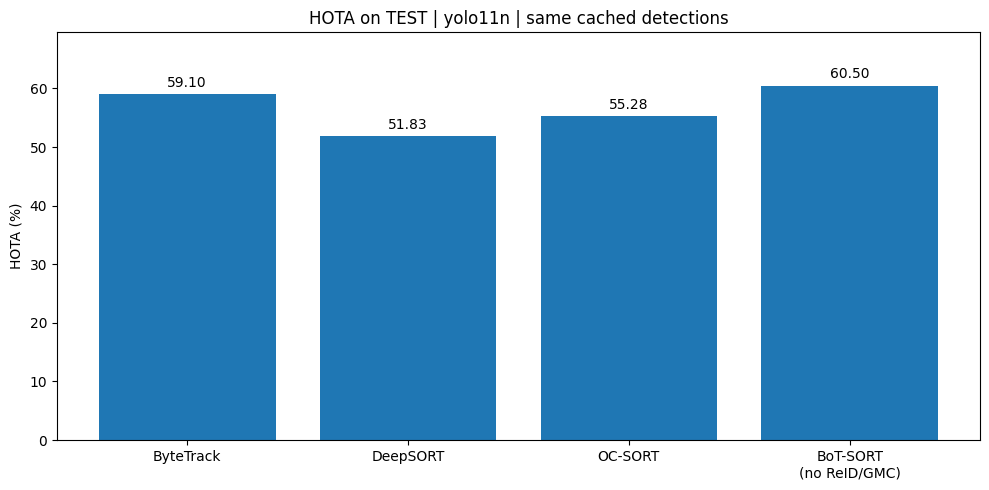

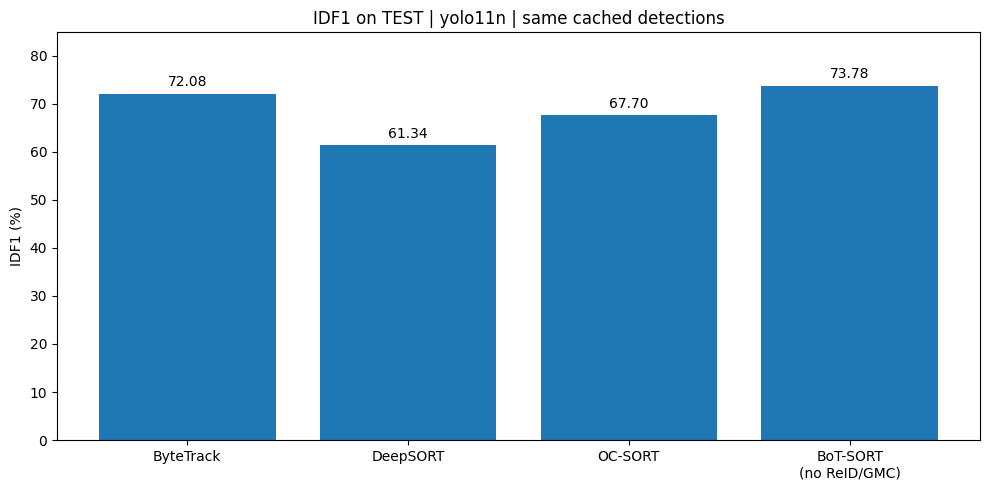

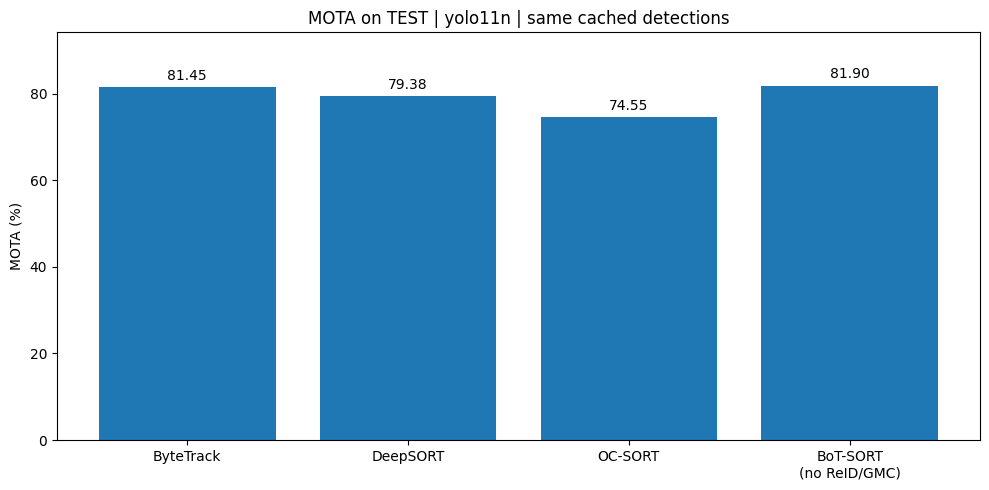

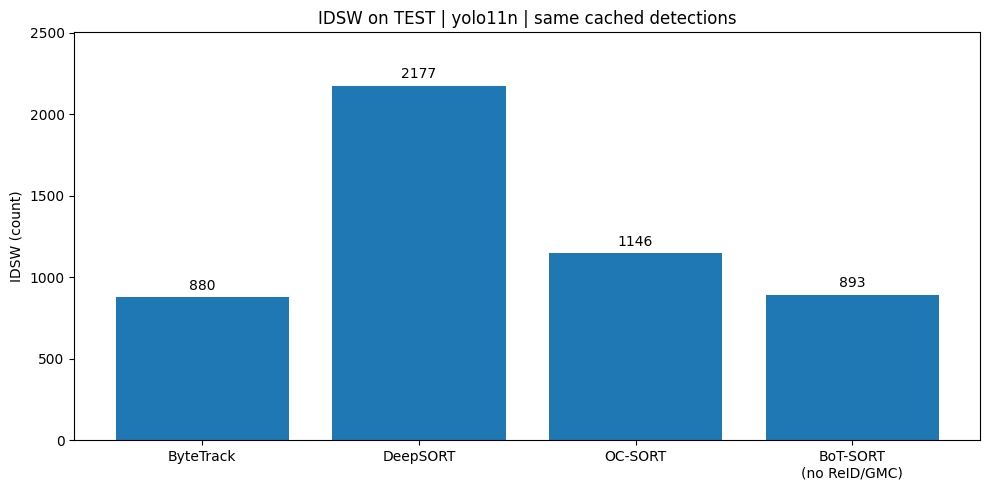

Results folder: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/tracking_four_trackers/yolo11n/8cfabc14eb1c7533
Speed file is separate. It must not be compared with legacy end-to-end FPS.

Original project files unchanged: True

CELL 12E completed successfully!


In [21]:
# ============================================================
# CELL 12E - FOUR TRACKER TABLE AND CHARTS
# ============================================================

# Show final comparison and generate charts
cc4_results = cc4.show_results()

# Verify original project files remain unchanged
print("\nOriginal project files unchanged:",
      cc4.check_integrity())

print("\nCELL 12E completed successfully!")

## Trajectories
Runs the tracker that scored best on **VAL** over all of MOT20-05 and saves the trajectories for the next stage (zones).
The CSV includes the **foot point** (bottom-centre of the box). It's where the person stands on the ground, so it's the right point for placing people into floor zones later.

In [16]:
# ============================================================
# CELL 13 — TRAJECTORIES: CSV + tracking video + trajectory video
# ============================================================

from collections import defaultdict, deque

if saved("trajectories", TRAJ_CSV, TRACK_VIDEO, TRAJ_VIDEO):
    traj = pd.read_csv(TRAJ_CSV)
    print(f"Trajectory points: {len(traj):,} | unique IDs: {traj.track_id.nunique():,}")
    print("Videos:", TRACK_VIDEO, "|", TRAJ_VIDEO)
else:
    byte_results = pd.read_csv(BYTE_GRID_CSV, index_col=0)
    deep_results = pd.read_csv(DEEP_GRID_CSV, index_col=0) if os.path.isfile(DEEP_GRID_CSV) else None

    BEST_BYTE = byte_results.iloc[0][["high", "low", "new", "buffer", "match"]].to_dict()
    BEST_BYTE["buffer"] = int(BEST_BYTE["buffer"])
    use_deep = deep_results is not None and deep_results.iloc[0]["IDF1"] > byte_results.iloc[0]["IDF1"]

    if use_deep:
        cfg = deep_results.iloc[0][["det_conf", "max_age", "n_init", "max_cos"]].to_dict()
        cfg["max_age"], cfg["n_init"] = int(cfg["max_age"]), int(cfg["n_init"])
        tracker_label, rows = "DeepSORT", run_deepsort(cfg, "full")[0]
    else:
        cfg = BEST_BYTE
        tracker_label, rows = "ByteTrack", run_bytetrack(cfg, "full")[0]
    print(f"Tracker (best on VAL): {tracker_label} {cfg}")

    # ---------- CSV ----------
    traj = pd.DataFrame(rows, columns=["frame", "track_id", "x1", "y1", "x2", "y2", "conf"])
    traj["center_x"] = (traj.x1 + traj.x2) / 2
    traj["center_y"] = (traj.y1 + traj.y2) / 2
    traj["foot_x"] = traj["center_x"]            # bottom-centre = where the person stands
    traj["foot_y"] = traj.y2
    traj = traj.sort_values(["frame", "track_id"]).round(2)
    traj.to_csv(TRAJ_CSV, index=False)

    # ---------- Videos ----------
    TRACK_RAW, TRAJ_RAW = "/content/tracking_raw.mp4", "/content/trajectory_raw.mp4"
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    w_track = cv2.VideoWriter(TRACK_RAW, fourcc, FPS, (IMG_W, IMG_H))
    w_traj  = cv2.VideoWriter(TRAJ_RAW,  fourcc, FPS, (IMG_W, IMG_H))
    history = defaultdict(lambda: deque(maxlen=50))
    by_frame = {f: g for f, g in traj.groupby("frame")}

    for f, name in enumerate(EVAL_FRAMES, 1):
        frame = cv2.imread(os.path.join(EVAL_IMG_DIR, name))
        track_img, traj_img = frame.copy(), frame.copy()
        if f in by_frame:
            for r in by_frame[f].itertuples(index=False):
                cx, cy = int(r.center_x), int(r.center_y)
                fx, fy = int(r.foot_x), int(r.foot_y)
                tid = str(r.track_id)
                history[r.track_id].append((fx, fy))

                cv2.circle(track_img, (cx, cy), 4, (0, 255, 0), -1)
                cv2.putText(track_img, tid, (cx + 6, cy - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1, cv2.LINE_AA)

                pts = list(history[r.track_id])
                for a, b in zip(pts, pts[1:]):
                    cv2.line(traj_img, a, b, (0, 255, 255), 2)
                cv2.circle(traj_img, (fx, fy), 4, (0, 255, 0), -1)
                cv2.putText(traj_img, tid, (fx + 6, fy - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1, cv2.LINE_AA)
        w_track.write(track_img)
        w_traj.write(traj_img)
        if f % 500 == 0:
            print(f"{f}/{len(EVAL_FRAMES)}")

    w_track.release()
    w_traj.release()

    # ---------- H.264 for browsers, then copy to Drive ----------
    for raw, final_path in [(TRACK_RAW, TRACK_VIDEO), (TRAJ_RAW, TRAJ_VIDEO)]:
        local = raw.replace("_raw", "_h264")
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", raw, "-c:v", "libx264",
                        "-pix_fmt", "yuv420p", "-movflags", "+faststart", local], check=True)
        shutil.copy2(local, final_path)

    # ---------- Completion check ----------
    print("\n" + "=" * 60)
    ok = True
    for path in [TRAJ_CSV, TRACK_VIDEO, TRAJ_VIDEO]:
        size = os.path.getsize(path) / 1024**2 if os.path.isfile(path) else 0
        ok &= size > 0
        print(f"{'✓' if size > 0 else '✗'} {path} ({size:.1f} MB)")
    print("Frames:", len(EVAL_FRAMES), "| trajectory points:", len(traj),
          "| unique IDs:", traj.track_id.nunique())
    print("COMPLETE ✓" if ok else "⚠ SOME OUTPUTS ARE MISSING")

Tracker (best on VAL): ByteTrack {'high': 0.6, 'low': 0.2, 'new': 0.7, 'buffer': 15, 'match': 0.7}
500/3315
1000/3315
1500/3315
2000/3315
2500/3315
3000/3315

✓ /content/drive/MyDrive/Crowd_AI_Project/runs_v4/trajectories_MOT20-05.csv (43.5 MB)
✓ /content/drive/MyDrive/Crowd_AI_Project/runs_v4/tracking_MOT20-05.mp4 (141.4 MB)
✓ /content/drive/MyDrive/Crowd_AI_Project/runs_v4/trajectories_MOT20-05.mp4 (185.7 MB)
Frames: 3315 | trajectory points: 647222 | unique IDs: 2299
COMPLETE ✓


In [17]:
# ============================================================
# CELL 14 — REPORT FIGURES: video stills + charts + tables
# Output: runs_v4/report_figures/ and report_figures.zip
# ============================================================

import cv2, torch
import matplotlib.pyplot as plt

if saved("report_figures", REPORT_ZIP):
    print("Report figures:", REPORT_ZIP)
else:
    OUT = f"{RUNS_DRIVE}/report_figures"
    os.makedirs(OUT, exist_ok=True)
    DET_NAME = get_track_detector()
    img_dir = find_seq_dir(EVAL_SEQUENCE)
    frames = list_frames(img_dir)

    # ---------- chart style (neutral, colorblind-checked palette, fixed order) ----------
    C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # series 1..4, never cycled
    INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
    plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 200, "font.size": 10,
                         "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
                         "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                         "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "figure.facecolor": "white", "axes.facecolor": "white"})

    def save_fig(fig, name):
        fig.tight_layout()
        fig.savefig(f"{OUT}/{name}", bbox_inches="tight")
        plt.close(fig)
        print("✓", name)

    def save_img(img, name, width=1400):
        h, w = img.shape[:2]
        if w > width:
            img = cv2.resize(img, (width, int(h * width / w)), interpolation=cv2.INTER_AREA)
        cv2.imwrite(f"{OUT}/{name}", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
        print("✓", name)

    def grouped_bars(ax, categories, series, labels, colors, fmt="{:.1f}"):
        n = len(series)
        width = 0.8 / n
        x = np.arange(len(categories))
        for i, (vals, lab, col) in enumerate(zip(series, labels, colors)):
            bars = ax.bar(x + (i - (n - 1) / 2) * width, vals, width * 0.92, label=lab, color=col)
            ax.bar_label(bars, labels=[fmt.format(v) for v in vals], fontsize=8, color=INK, padding=2)
        ax.set_xticks(x, categories)

    # ---------- 1. Video stills ----------
    def grab(video, frame_no):
        cap = cv2.VideoCapture(video)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no - 1)
        ok, img = cap.read()
        cap.release()
        return img if ok else None

    for f in [500, 1700, 3000]:                     # 500 = VAL part, 1700 & 3000 = TEST part
        for video, tag in [(TRACK_VIDEO, "tracking"), (TRAJ_VIDEO, "trajectory")]:
            img = grab(video, f)
            if img is not None:
                save_img(img, f"still_{tag}_f{f}.jpg")

    img = grab(TRAJ_VIDEO, 3000)
    if img is not None:
        h, w = img.shape[:2]
        crop = img[int(h * 0.30):int(h * 0.70), int(w * 0.30):int(w * 0.70)]
        save_img(cv2.resize(crop, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC), "zoom_trajectory_f3000.jpg")

    F = 3000
    raw = cv2.imread(os.path.join(img_dir, frames[F - 1]))
    save_img(raw, f"raw_f{F}.jpg")
    gt = pedestrians(load_gt(EVAL_SEQUENCE))
    gt_img = raw.copy()
    for r in gt[gt.frame == F].itertuples(index=False):
        cv2.rectangle(gt_img, (int(r.x), int(r.y)), (int(r.x + r.w), int(r.y + r.h)), (0, 200, 0), 1)
    save_img(gt_img, f"ground_truth_f{F}.jpg")
    det = pd.read_parquet(f"{RUNS_DRIVE}/detections_{DET_NAME}_{EVAL_SEQUENCE}.parquet")
    det_img = raw.copy()
    for r in det[(det.frame == F) & (det.conf >= 0.6)].itertuples(index=False):
        cv2.rectangle(det_img, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), (214, 120, 42), 1)
    save_img(det_img, f"detections_f{F}.jpg")

    # ---------- 2. Charts ----------
    dc = pd.read_csv(DET_COMPARE_CSV, index_col=0)
    fps = pd.read_csv(FPS_CSV, index_col=0)
    final = pd.read_csv(FINAL_CSV, index_col=0)
    byte = pd.read_csv(BYTE_GRID_CSV, index_col=0)
    diff = pd.read_csv(DIFFICULTY_CSV)
    traj = pd.read_csv(TRAJ_CSV)

    fig, ax = plt.subplots(figsize=(7, 3.8))
    grouped_bars(ax, dc.index, [dc["TEST mAP50"] * 100, dc["TEST mAP50-95"] * 100], ["mAP50", "mAP50-95"], C[:2])
    ax.set_ylabel("Score on TEST (%)")
    ax.set_title(f"Detector accuracy on TEST (MOT20-05 frames {SPLIT_FRAME + 1}+), imgsz {IMG_SIZE}", loc="left")
    ax.legend(frameon=False, loc="upper left", ncols=2)
    ax.set_ylim(0, 100)
    save_fig(fig, "fig_detectors_test.png")

    both = dc.join(fps[["FPS"]], how="inner")
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.scatter(both["FPS"], both["TEST mAP50-95"] * 100, s=70, color=C[0], edgecolor="white", linewidth=2, zorder=3)
    for name, r in both.iterrows():
        ax.annotate(name, (r["FPS"], r["TEST mAP50-95"] * 100), textcoords="offset points", xytext=(8, 4), fontsize=9)
    ax.axvline(FPS, color=MUTED, linestyle="--", linewidth=1)
    ax.text(FPS, ax.get_ylim()[1], " 25 FPS = real-time", color=MUTED, fontsize=8, va="top")
    ax.set_xlabel("Detection speed (FPS, batch 1, end-to-end)")
    ax.set_ylabel("TEST mAP50-95 (%)")
    ax.set_title("Speed vs accuracy of the detectors", loc="left")
    save_fig(fig, "fig_speed_vs_accuracy.png")

    metrics = ["HOTA", "IDF1", "MOTA"]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    grouped_bars(ax, metrics, [final.loc[t, metrics].values for t in final.index], list(final.index), C[:len(final)])
    ax.set_ylabel("Score on TEST (%)")
    ax.set_ylim(0, 100)
    ax.set_title("Tracking quality on TEST (TrackEval)", loc="left")
    ax.legend(frameon=False, loc="upper left", ncols=3, fontsize=8)
    save_fig(fig, "fig_trackers_test.png")

    fig, ax = plt.subplots(figsize=(7, 2.6))
    bars = ax.barh(final.index[::-1], final["IDSW"][::-1], color=C[0], height=0.55)
    ax.bar_label(bars, labels=[f"{int(v):,}" for v in final["IDSW"][::-1]], padding=4, fontsize=9, color=INK)
    ax.set_xlabel("ID switches on TEST (lower is better)")
    ax.set_title("Identity switches per tracker", loc="left")
    ax.grid(axis="y", visible=False)
    save_fig(fig, "fig_id_switches_test.png")

    val_row, test_row = byte.iloc[0], final.loc["ByteTrack (tuned)"]
    fig, ax = plt.subplots(figsize=(7, 3.6))
    grouped_bars(ax, metrics, [val_row[metrics].values, test_row[metrics].values],
                 ["VAL (used for tuning)", "TEST (never seen)"], C[:2])
    ax.set_ylim(0, 100)
    ax.set_ylabel("Score (%)")
    ax.set_title("Tuned ByteTrack: VAL vs TEST — no overfitting", loc="left")
    ax.legend(frameon=False, loc="upper left", ncols=2)
    save_fig(fig, "fig_val_vs_test.png")

    fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
    for ax, col, title in zip(axes, ["Avg People/Frame", "Heavy Occlusion %", "Avg Brightness"],
                              ["People per frame", "Heavily occluded (%)", "Brightness (0-255)"]):
        bars = ax.bar(diff["Data"], diff[col], color=C[0], width=0.6)
        ax.bar_label(bars, labels=[f"{v:.0f}" for v in diff[col]], fontsize=8, padding=2, color=INK)
        ax.set_title(title, loc="left", fontsize=10)
        ax.tick_params(axis="x", rotation=45, labelsize=8)
    fig.suptitle("MOT20 difficulty: training sequences vs VAL / TEST", x=0.01, ha="left")
    save_fig(fig, "fig_difficulty.png")

    lengths = traj.groupby("track_id").size() / FPS
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.hist(lengths, bins=40, color=C[0], edgecolor="white", linewidth=1)
    ax.axvline(lengths.median(), color=INK, linestyle="--", linewidth=1)
    ax.text(lengths.median(), ax.get_ylim()[1], f" median {lengths.median():.1f} s", fontsize=8, va="top")
    ax.set_xlabel("Track length (seconds)")
    ax.set_ylabel("Number of tracks")
    ax.set_title("How long each person is followed (MOT20-05, tuned ByteTrack)", loc="left")
    save_fig(fig, "fig_track_lengths.png")

    # ---------- 3. Tables for the report ----------
    pd.set_option("display.width", 250)
    print("\n===== DETECTOR COMPARISON =====\n", dc.to_string())
    print("\n===== DETECTOR FPS =====\n", fps.to_string())
    print("\n===== DIFFICULTY =====\n", diff.to_string(index=False))
    print("\n===== TRACKING TEST =====\n", final.to_string())
    print("\n===== TRAJECTORIES =====")
    print(f"rows {len(traj)} | unique IDs {traj.track_id.nunique()} | frames {traj.frame.nunique()}")
    print(f"track length (s): mean {lengths.mean():.1f} | median {lengths.median():.1f} | max {lengths.max():.1f}")
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

    shutil.make_archive(REPORT_ZIP[:-4], "zip", OUT)
    print(f"\n✓ Download this single file: {REPORT_ZIP}")

✓ still_tracking_f500.jpg
✓ still_trajectory_f500.jpg
✓ still_tracking_f1700.jpg
✓ still_trajectory_f1700.jpg
✓ still_tracking_f3000.jpg
✓ still_trajectory_f3000.jpg
✓ zoom_trajectory_f3000.jpg
✓ raw_f3000.jpg
✓ ground_truth_f3000.jpg
✓ detections_f3000.jpg
✓ fig_detectors_test.png
✓ fig_speed_vs_accuracy.png
✓ fig_trackers_test.png
✓ fig_id_switches_test.png
✓ fig_val_vs_test.png
✓ fig_difficulty.png
✓ fig_track_lengths.png

===== DETECTOR COMPARISON =====
          Params (M)   VAL P   VAL R  VAL mAP50  VAL mAP50-95  TEST P  TEST R  TEST mAP50  TEST mAP50-95
Model                                                                                                  
yolov8n        3.14  0.8303  0.8718     0.8759        0.5250  0.8353  0.8745      0.8833         0.5384
yolov8s       11.14  0.8463  0.8804     0.8838        0.5225  0.8512  0.8845      0.8858         0.5387
yolov8m       25.86  0.8415  0.8566     0.8679        0.5188  0.8476  0.8615      0.8749         0.5390
yolo11n        2.

# Stage 4 — Zone-based crowd analysis
1. Splits the camera view into a **grid of zones** (default 3 × 4 = 12). Hand-drawn polygons can be plugged in via `CUSTOM_ZONES` in CONFIG.
2. Puts every person into a zone by their **foot point** (bottom-centre of the box = where they stand).
3. Computes, **every second and for every zone**: count, density, floor coverage, two crowding levels, inflow / outflow, appear / disappear, speed, direction and waiting time, plus a zone-to-zone **transition table** (input for the later graph stage).
   - **own level:** LOW / MEDIUM / HIGH compared with the zone's *own* history (median and 90th percentile of its counts).
   - **floor level:** physical crowding, *comparable between zones*: people × typical person size in the zone ÷ zone area, which corrects for perspective.
   - All thresholds are **learned on the VAL half only** and applied unchanged to TEST.
4. Runs the same computation on the **ground truth** and measures how accurate the zone numbers are.
5. Figures (density heatmap, temporal congestion map, flow map, transition matrix) and a **zone video**.

No GPU is needed. Cells 15–19 always recompute because they take seconds and give identical results; the figures and video are skipped when already saved.

In [18]:
# ============================================================
# CELL 15 — ZONES SETUP: load trajectories + ground truth for MOT20-05
# ============================================================

import cv2

SEQ = EVAL_SEQUENCE
IMG_DIR = find_seq_dir(SEQ)
FRAMES = list_frames(IMG_DIR)
N_FRAMES = len(FRAMES)
H, W = cv2.imread(os.path.join(IMG_DIR, FRAMES[0])).shape[:2]
FRAME_IDX = range(1, N_FRAMES + 1)
N_STEPS = (N_FRAMES + STEP - 1) // STEP
FIRST_TEST_STEP = SPLIT_FRAME // STEP + (1 if SPLIT_FRAME % STEP else 0)  # first step that starts in TEST

def foot_table(df, id_col, fx, fy, box_area):
    return pd.DataFrame({"frame": df["frame"].astype(int).values,
                         "track_id": df[id_col].astype(int).values,
                         "foot_x": np.clip(fx, 0, W - 1), "foot_y": np.clip(fy, 0, H - 1),
                         "box_area": np.asarray(box_area, float)})    # person size, for floor coverage

# Tracker trajectories (tuned ByteTrack, cell 13)
traj = pd.read_csv(TRAJ_CSV)
TRK = foot_table(traj, "track_id", traj["foot_x"].values, traj["foot_y"].values,
                 ((traj.x2 - traj.x1) * (traj.y2 - traj.y1)).values)

# Ground truth: valid pedestrians, foot = bottom-centre of the box
gt = pedestrians(load_gt(SEQ))
GT_ALL = foot_table(gt, "id", (gt.x + gt.w / 2).values, (gt.y + gt.h).values, (gt.w * gt.h).values)
gt_vis = gt[gt["vis"] >= GT_MIN_VIS]
GT_VIS = foot_table(gt_vis, "id", (gt_vis.x + gt_vis.w / 2).values, (gt_vis.y + gt_vis.h).values,
                    (gt_vis.w * gt_vis.h).values)

print(f"{SEQ}: {N_FRAMES} frames, {W}x{H}, {N_STEPS} one-second steps (TEST starts at step {FIRST_TEST_STEP})")
print(f"Tracker rows: {len(TRK):,} | tracks: {TRK.track_id.nunique():,} | people/frame: {len(TRK) / N_FRAMES:.1f}")
print(f"GT rows: {len(GT_ALL):,} | people/frame: {len(GT_ALL) / N_FRAMES:.1f} "
      f"| visible >= {GT_MIN_VIS}: {len(GT_VIS) / N_FRAMES:.1f}/frame")

MOT20-05: 3315 frames, 1654x1080, 133 one-second steps (TEST starts at step 67)
Tracker rows: 647,222 | tracks: 2,299 | people/frame: 195.2
GT rows: 646,344 | people/frame: 195.0 | visible >= 0.25: 159.3/frame


In [19]:
# ============================================================
# CELL 16 — ZONES: grid (or custom polygons) → mask, areas, neighbours, overlay image
# ============================================================

def grid_zones(rows, cols):
    zones = []
    for r in range(rows):
        for c in range(cols):
            x0, x1 = round(c * W / cols), round((c + 1) * W / cols) - 1
            y0, y1 = round(r * H / rows), round((r + 1) * H / rows) - 1
            zones.append({"id": r * cols + c, "name": f"Z{r * cols + c}", "row": r, "col": c,
                          "polygon": [[x0, y0], [x1, y0], [x1, y1], [x0, y1]]})
    return zones

if CUSTOM_ZONES:
    ZONES = [{"id": i, "name": name, "row": None, "col": None, "polygon": poly}
             for i, (name, poly) in enumerate(CUSTOM_ZONES.items())]
else:
    ZONES = grid_zones(GRID_ROWS, GRID_COLS)
ZONE_IDS = [z["id"] for z in ZONES]
ZONE_NAME = {z["id"]: z["name"] for z in ZONES}

# Pixel mask: value = zone id, -1 = outside every zone
ZONE_MASK = np.full((H, W), -1, np.int16)
for z in ZONES:
    cv2.fillPoly(ZONE_MASK, [np.array(z["polygon"], np.int32)], int(z["id"]))

AREA = {z["id"]: int((ZONE_MASK == z["id"]).sum()) for z in ZONES}
CENTROID = {}
for z in ZONES:
    ys, xs = np.nonzero(ZONE_MASK == z["id"])
    CENTROID[z["id"]] = (int(xs.mean()), int(ys.mean()))

# Neighbours = zones sharing a border (used later as graph edges)
kernel = np.ones((5, 5), np.uint8)
NEIGHBOURS = {}
for z in ZONES:
    grown = cv2.dilate((ZONE_MASK == z["id"]).astype(np.uint8), kernel)
    NEIGHBOURS[z["id"]] = sorted(int(v) for v in np.unique(ZONE_MASK[grown > 0]) if v >= 0 and v != z["id"])

for z in ZONES:
    z.update(area_px=AREA[z["id"]], centroid=CENTROID[z["id"]], neighbours=NEIGHBOURS[z["id"]])
with open(f"{ZONES_DIR}/zone_definition.json", "w") as f:
    json.dump({"sequence": SEQ, "image_size": [W, H], "grid": None if CUSTOM_ZONES else [GRID_ROWS, GRID_COLS],
               "zones": ZONES}, f, indent=1)

# Overlay image
overlay = cv2.imread(os.path.join(IMG_DIR, FRAMES[0]))
for z in ZONES:
    cv2.polylines(overlay, [np.array(z["polygon"], np.int32)], True, (255, 255, 255), 2)
    cx, cy = CENTROID[z["id"]]
    cv2.putText(overlay, z["name"], (cx - 25, cy + 12), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 6, cv2.LINE_AA)
    cv2.putText(overlay, z["name"], (cx - 25, cy + 12), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 2, cv2.LINE_AA)
cv2.imwrite(f"{FIG_DIR}/zones_overlay.jpg", overlay, [cv2.IMWRITE_JPEG_QUALITY, 90])

print(f"✓ {len(ZONES)} zones | zone area {min(AREA.values()):,}–{max(AREA.values()):,} px")
for z in ZONES:
    print(f"  {z['name']}: neighbours {[ZONE_NAME[n] for n in z['neighbours']]}")

✓ 12 zones | zone area 148,680–149,040 px
  Z0: neighbours ['Z1', 'Z4', 'Z5']
  Z1: neighbours ['Z0', 'Z2', 'Z4', 'Z5', 'Z6']
  Z2: neighbours ['Z1', 'Z3', 'Z5', 'Z6', 'Z7']
  Z3: neighbours ['Z2', 'Z6', 'Z7']
  Z4: neighbours ['Z0', 'Z1', 'Z5', 'Z8', 'Z9']
  Z5: neighbours ['Z0', 'Z1', 'Z2', 'Z4', 'Z6', 'Z8', 'Z9', 'Z10']
  Z6: neighbours ['Z1', 'Z2', 'Z3', 'Z5', 'Z7', 'Z9', 'Z10', 'Z11']
  Z7: neighbours ['Z2', 'Z3', 'Z6', 'Z10', 'Z11']
  Z8: neighbours ['Z4', 'Z5', 'Z9']
  Z9: neighbours ['Z4', 'Z5', 'Z6', 'Z8', 'Z10']
  Z10: neighbours ['Z5', 'Z6', 'Z7', 'Z9', 'Z11']
  Z11: neighbours ['Z6', 'Z7', 'Z10']


In [20]:
# ============================================================
# CELL 17 — ASSIGN PEOPLE TO ZONES (foot point) + remove border jitter
# ============================================================

def smooth_runs(z):
    """Replace zone visits shorter than MIN_RUN frames by the neighbouring visit."""
    change = np.r_[True, z[1:] != z[:-1]]
    starts = np.flatnonzero(change)
    lens = np.diff(np.r_[starts, len(z)])
    vals = z[starts].copy()
    if len(vals) > 1:
        for i in range(len(vals)):
            if lens[i] < MIN_RUN:
                vals[i] = vals[i - 1] if i > 0 else vals[i + 1]
    return np.repeat(vals, lens)

def assign_zones(df):
    df = df.copy()
    df["zone_raw"] = ZONE_MASK[df.foot_y.round().astype(int).values, df.foot_x.round().astype(int).values]
    df = df[df.zone_raw >= 0].sort_values(["track_id", "frame"]).reset_index(drop=True)
    zones = df.zone_raw.values
    bounds = np.flatnonzero(np.r_[True, df.track_id.values[1:] != df.track_id.values[:-1], True])
    smoothed = np.empty_like(zones)
    for a, b in zip(bounds[:-1], bounds[1:]):
        smoothed[a:b] = smooth_runs(zones[a:b])
    df["zone"] = smoothed
    return df

t0 = time.time()
TRK_Z = assign_zones(TRK)
GT_ALL_Z = assign_zones(GT_ALL)
GT_VIS_Z = assign_zones(GT_VIS)

def raw_changes(df):
    same = df.track_id.values[1:] == df.track_id.values[:-1]
    raw = (same & (df.zone_raw.values[1:] != df.zone_raw.values[:-1])).sum()
    smooth = (same & (df.zone.values[1:] != df.zone.values[:-1])).sum()
    return raw, smooth

r, s = raw_changes(TRK_Z)
print(f"✓ Zones assigned in {time.time() - t0:.0f}s")
print(f"Tracker zone changes: {r:,} raw → {s:,} after removing border jitter ({100 * (1 - s / max(r, 1)):.0f}% were jitter)")
# Check: nobody lost (with a full grid, every foot point lies in a zone)
print("Check — people per frame preserved:", len(TRK_Z) == len(TRK) if not CUSTOM_ZONES else "custom zones (people outside zones are dropped)")

✓ Zones assigned in 0s
Tracker zone changes: 4,395 raw → 2,551 after removing border jitter (42% were jitter)
Check — people per frame preserved: True


In [21]:
# ============================================================
# CELL 18 — PER-ZONE, PER-SECOND STATISTICS (tracker and ground truth)
# ============================================================

STEPS = range(N_STEPS)

def zone_statistics(df):
    df = df.sort_values(["track_id", "frame"]).reset_index(drop=True)
    df["step"] = (df.frame - 1) // STEP
    same_track = np.r_[False, df.track_id.values[1:] == df.track_id.values[:-1]]

    # ---- counts (per frame, then per step) ----
    per_frame = (df.groupby(["frame", "zone"]).size().unstack(fill_value=0)
                 .reindex(index=FRAME_IDX, columns=ZONE_IDS, fill_value=0))
    step_of_frame = (np.asarray(per_frame.index) - 1) // STEP
    count = per_frame.groupby(step_of_frame).mean()
    max_count = per_frame.groupby(step_of_frame).max()

    # ---- level calibration: learned on VAL frames only ----
    val = np.asarray(per_frame.index) <= SPLIT_FRAME
    own_lo = per_frame[val].quantile(LEVEL_Q[0])                       # per zone
    own_hi = per_frame[val].quantile(LEVEL_Q[1]).clip(lower=1.0)
    person_area = (df[df.frame <= SPLIT_FRAME].groupby("zone").box_area.median()
                   .reindex(ZONE_IDS))
    person_area = person_area.fillna(person_area.median())             # zones nobody visited in VAL
    zone_area = pd.Series(AREA).reindex(ZONE_IDS)
    coverage_pf = per_frame * (person_area / zone_area)               # per frame, per zone
    floor_lo, floor_hi = np.quantile(coverage_pf[val].values.ravel(), LEVEL_Q)   # pooled over ALL zones
    calib = pd.DataFrame({"zone": ZONE_IDS, "name": [ZONE_NAME[z] for z in ZONE_IDS],
                          "own_low_max": own_lo.values, "own_high_min": own_hi.values,
                          "person_area_px": person_area.values, "zone_area_px": zone_area.values,
                          "floor_low_max": floor_lo, "floor_high_min": floor_hi})

    # ---- transitions (zone changes inside a track) ----
    moved = same_track & np.r_[False, df.zone.values[1:] != df.zone.values[:-1]]
    idx = np.flatnonzero(moved)
    trans = pd.DataFrame({"step": df.step.values[idx], "from_zone": df.zone.values[idx - 1],
                          "to_zone": df.zone.values[idx]})
    trans_table = trans.groupby(["step", "from_zone", "to_zone"]).size().rename("n").reset_index()
    inflow = trans.groupby(["step", "to_zone"]).size().unstack(fill_value=0)
    outflow = trans.groupby(["step", "from_zone"]).size().unstack(fill_value=0)

    # ---- tracks starting / ending inside a zone ----
    first, last = df.groupby("track_id").head(1), df.groupby("track_id").tail(1)
    appear = first.groupby(["step", "zone"]).size().unstack(fill_value=0)
    disappear = last.groupby(["step", "zone"]).size().unstack(fill_value=0)

    # ---- speed and direction (foot displacement over SPEED_LAG frames) ----
    g = df.groupby("track_id")
    dt = (df.frame - g.frame.shift(SPEED_LAG)) / FPS
    ok = dt.notna() & (dt > 0) & (dt <= 2 * SPEED_LAG / FPS)
    df["vx"] = np.where(ok, (df.foot_x - g.foot_x.shift(SPEED_LAG)) / dt, np.nan)
    df["vy"] = np.where(ok, (df.foot_y - g.foot_y.shift(SPEED_LAG)) / dt, np.nan)
    df["speed"] = np.hypot(df.vx, df.vy)

    # ---- waiting time: seconds since the person entered their current zone ----
    new_visit = ~same_track | np.r_[True, df.zone.values[1:] != df.zone.values[:-1]]
    df["visit"] = np.cumsum(new_visit)
    df["wait_s"] = (df.frame - df.groupby("visit").frame.transform("min")) / FPS

    motion = df.groupby(["step", "zone"]).agg(speed=("speed", "mean"), vx=("vx", "mean"),
                                              vy=("vy", "mean"), wait_s=("wait_s", "mean"))

    def long(m, name):
        m = m.reindex(index=STEPS, columns=ZONE_IDS, fill_value=0)
        m.index.name, m.columns.name = "step", "zone"
        return m.stack().rename(name)

    out = pd.concat([long(count, "count"), long(max_count, "max_count"), long(inflow, "inflow"),
                     long(outflow, "outflow"), long(appear, "appear"), long(disappear, "disappear")], axis=1)
    out = out.join(motion)
    out = out.reset_index()
    out["zone_name"] = out.zone.map(ZONE_NAME)
    out["t_start_s"] = out.step * STEP / FPS
    out["split"] = np.where(out.step >= FIRST_TEST_STEP, "TEST", "VAL")
    out["density_per_100x100px"] = out["count"] / out.zone.map(AREA) * 1e4
    out["level_own"] = level3(out["count"], out.zone.map(own_lo), out.zone.map(own_hi))
    out["floor_coverage"] = out["count"] * out.zone.map(person_area) / out.zone.map(zone_area)
    out["level_floor"] = level3(out["floor_coverage"], floor_lo, floor_hi)
    out["dir_deg"] = np.degrees(np.arctan2(-out.vy, out.vx))          # 0 = right, 90 = up (image)
    for c in ["speed", "vx", "vy", "wait_s", "dir_deg"]:
        out[c] = out[c].round(2)
    return out, trans_table, per_frame, calib, df

t0 = time.time()
STATS, TRANS, PF, CALIB, TRK_M = zone_statistics(TRK_Z)
STATS_GT, TRANS_GT, PF_GT, CALIB_GT, _ = zone_statistics(GT_ALL_Z)
STATS_GV, TRANS_GV, PF_GV, CALIB_GV, _ = zone_statistics(GT_VIS_Z)

STATS.round(4).to_csv(f"{ZONES_DIR}/zone_stats_{SEQ}.csv", index=False)
STATS_GT.round(4).to_csv(f"{ZONES_DIR}/zone_stats_GT_{SEQ}.csv", index=False)
TRANS.to_csv(f"{ZONES_DIR}/zone_transitions_{SEQ}.csv", index=False)
CALIB.round(4).to_csv(f"{ZONES_DIR}/zone_level_calibration_{SEQ}.csv", index=False)

print("LEVEL THRESHOLDS (learned on VAL frames 1-%d only)" % SPLIT_FRAME)
print(CALIB.set_index("name")[["own_low_max", "own_high_min", "person_area_px"]].round(1).to_string())
print(f"Floor coverage (all zones): LOW <= {CALIB.floor_low_max[0]:.3f} < MEDIUM < {CALIB.floor_high_min[0]:.3f} <= HIGH\n")

# ---- Consistency checks ----
print(f"✓ Statistics computed in {time.time() - t0:.0f}s: {len(STATS):,} rows ({N_STEPS} steps × {len(ZONE_IDS)} zones)")
frame_total = PF.sum(axis=1).values
tracked = TRK.groupby("frame").size().reindex(FRAME_IDX, fill_value=0).values   # original trajectory rows
print("Check 1 — zone counts add up to people tracked in every frame:", bool((frame_total == tracked).all()))
print("Check 2 — every move counted once as outflow and once as inflow:",
      int(STATS.inflow.sum()) == int(STATS.outflow.sum()) == int(TRANS.n.sum()))

summary = (STATS.groupby("zone_name", sort=False)
           .agg(mean_count=("count", "mean"), max_count=("max_count", "max"),
                inflow_total=("inflow", "sum"), outflow_total=("outflow", "sum"),
                mean_speed_px_s=("speed", "mean"), mean_wait_s=("wait_s", "mean"),
                mean_floor_coverage=("floor_coverage", "mean"),
                high_own_pct=("level_own", lambda s: 100 * (s == "HIGH").mean()),
                high_floor_pct=("level_floor", lambda s: 100 * (s == "HIGH").mean())))
print("\nPER-ZONE SUMMARY (tracker, whole video)")
print(summary.round(1).to_string())

LEVEL THRESHOLDS (learned on VAL frames 1-1657 only)
      own_low_max  own_high_min  person_area_px
name                                           
Z0           17.0          23.0          7980.6
Z1           15.0          23.0          7482.9
Z2           18.0          26.0          7764.1
Z3           18.0          22.0          8168.6
Z4           19.0          30.0         10054.3
Z5           18.0          23.0         10013.1
Z6           18.0          28.0         10372.6
Z7           18.0          28.0         10006.8
Z8           12.0          17.0         12618.7
Z9           14.0          19.0         12813.3
Z10          15.0          20.0         12439.2
Z11          13.0          16.0         12719.4
Floor coverage (all zones): LOW <= 1.078 < MEDIUM < 1.619 <= HIGH

✓ Statistics computed in 1s: 1,596 rows (133 steps × 12 zones)
Check 1 — zone counts add up to people tracked in every frame: True
Check 2 — every move counted once as outflow and once as inflow: True

PER-ZO

## How accurate are the zone numbers?
The ground truth (GT) gives the true position of every person, so the same zone statistics computed from GT are the "correct answer".
We compare tracker vs GT for every zone and every second, on the **TEST** half (frames 1658+) and on the full video.

- **GT (all):** every annotated pedestrian, including people almost completely hidden. No camera-based system can see those, so this is a strict reference.
- **GT (visible ≥ 25%):** only people at least a quarter visible. This is a fairer reference for a camera system.

In [22]:
# ============================================================
# CELL 19 — ACCURACY CHECK vs GROUND TRUTH
# ============================================================

def compare(trk, ref, ref_name):
    m = trk.merge(ref, on=["step", "zone"], suffixes=("_trk", "_gt"))
    rows = []
    for split_name, sel in [("TEST", m.split_trk == "TEST"), ("Full video", np.ones(len(m), bool))]:
        mm = m[sel]
        for var in ["count", "inflow", "outflow"]:
            a, b = mm[f"{var}_trk"].values, mm[f"{var}_gt"].values
            mae = np.abs(a - b).mean()
            rows.append({"reference": ref_name, "split": split_name, "quantity": var,
                         "GT mean": b.mean(), "tracker mean": a.mean(), "MAE": mae,
                         "relative MAE %": 100 * mae / max(b.mean(), 1e-9),
                         "bias": (a - b).mean(), "correlation r": np.corrcoef(a, b)[0, 1]})
        # Level agreement: does our system give a zone-second the same LOW/MEDIUM/HIGH as the truth?
        # (each source uses its own thresholds, learned on its own VAL frames)
        for lv in ["level_own", "level_floor"]:
            rows.append({"reference": ref_name, "split": split_name, "quantity": lv,
                         "level agreement %": 100 * (mm[f"{lv}_trk"] == mm[f"{lv}_gt"]).mean()})
    return pd.DataFrame(rows), m

ACC_ALL, M_ALL = compare(STATS, STATS_GT, "GT (all)")
ACC_VIS, M_VIS = compare(STATS, STATS_GV, f"GT (visible >= {GT_MIN_VIS})")
ACC = pd.concat([ACC_ALL, ACC_VIS], ignore_index=True)
ACC.round(3).to_csv(f"{ZONES_DIR}/zone_accuracy_{SEQ}.csv", index=False)

pd.set_option("display.width", 220)
print("ZONE ACCURACY — tracker vs ground truth (per zone, per second)")
print(ACC.round(2).to_string(index=False))

per_zone = (M_VIS[M_VIS.split_trk == "TEST"]
            .assign(err=lambda d: (d.count_trk - d.count_gt).abs())
            .groupby("zone").agg(gt_mean=("count_gt", "mean"), mae=("err", "mean")))
per_zone.index = per_zone.index.map(ZONE_NAME)
print("\nCount error per zone on TEST (vs visible GT):")
print(per_zone.round(2).to_string())

ZONE ACCURACY — tracker vs ground truth (per zone, per second)
           reference      split    quantity  GT mean  tracker mean  MAE  relative MAE %  bias  correlation r  level agreement %
            GT (all)       TEST       count    16.03         16.01 1.97           12.30 -0.02           0.91                NaN
            GT (all)       TEST      inflow     1.49          1.58 0.58           38.79  0.09           0.79                NaN
            GT (all)       TEST     outflow     1.49          1.58 0.59           39.47  0.09           0.80                NaN
            GT (all)       TEST   level_own      NaN           NaN  NaN             NaN   NaN            NaN              78.28
            GT (all)       TEST level_floor      NaN           NaN  NaN             NaN   NaN            NaN              78.79
            GT (all) Full video       count    16.25         16.27 1.91           11.76  0.02           0.92                NaN
            GT (all) Full video      infl

In [23]:
# ============================================================
# CELL 20 — FIGURES
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

if saved("zones_figures", ZONES_ZIP):
    print("Zone figures:", FIG_DIR)
else:
    C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
    INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
    plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 200, "font.size": 10, "axes.edgecolor": "#c3c2b7",
                         "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                         "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                         "axes.spines.top": False, "axes.spines.right": False})
    BLUES = LinearSegmentedColormap.from_list("blues", ["#f7fbff", "#9ec5f4", "#2a78d6", "#0d366b"])
    HEAT = LinearSegmentedColormap.from_list("heat", [(0.92, 0.41, 0.20, 0.0), (0.92, 0.41, 0.20, 0.55),
                                                      (1.0, 0.85, 0.40, 0.95)])
    frame0 = cv2.cvtColor(cv2.imread(os.path.join(IMG_DIR, FRAMES[SPLIT_FRAME])), cv2.COLOR_BGR2RGB)

    def save(fig, name):
        fig.tight_layout()
        fig.savefig(f"{FIG_DIR}/{name}", bbox_inches="tight")
        plt.close(fig)
        print("✓", name)

    def draw_grid(ax, color="white"):
        for z in ZONES:
            poly = np.array(z["polygon"] + [z["polygon"][0]])
            ax.plot(poly[:, 0], poly[:, 1], color=color, linewidth=0.8, alpha=0.8)
            cx, cy = CENTROID[z["id"]]
            ax.text(cx, cy, z["name"], color=color, fontsize=8, ha="center", va="center", alpha=0.9)

    # ---- 6a. Density heatmap: where people spend time ----
    acc = np.zeros((H, W), np.float32)
    np.add.at(acc, (TRK.foot_y.round().astype(int).values, TRK.foot_x.round().astype(int).values), 1)
    heat = cv2.GaussianBlur(acc, (0, 0), sigmaX=18)
    heat = heat / np.percentile(heat[heat > 0], 99.5)
    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.imshow((frame0 * 0.45).astype(np.uint8))
    im = ax.imshow(np.clip(heat, 0, 1), cmap=HEAT, vmin=0, vmax=1)
    draw_grid(ax)
    ax.set_axis_off()
    cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
    cb.set_label("Relative time spent by people (foot points)")
    ax.set_title(f"Crowd density heatmap — {SEQ}, whole video", loc="left")
    save(fig, "density_heatmap.png")

    # ---- 6b. Temporal congestion map: zone × time ----
    mat = STATS.pivot(index="zone", columns="step", values="count").reindex(ZONE_IDS)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    im = ax.imshow(mat.values, aspect="auto", cmap=BLUES, interpolation="nearest")
    ax.set_yticks(range(len(ZONE_IDS)), [ZONE_NAME[z] for z in ZONE_IDS])
    ax.set_xlabel("Time (seconds)")
    ax.axvline(FIRST_TEST_STEP - 0.5, color=INK, linestyle="--", linewidth=1)
    ax.text(FIRST_TEST_STEP, -0.8, " TEST half →", fontsize=8, va="bottom")
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01).set_label("People in zone (mean per second)")
    ax.set_title("Temporal congestion map: people per zone over time", loc="left")
    save(fig, "temporal_congestion_map.png")

    # ---- 6c. Flow map: mean walking direction and speed per zone ----
    flow = TRK_M.groupby("zone").agg(vx=("vx", "mean"), vy=("vy", "mean"), speed=("speed", "mean"))
    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.imshow((frame0 * 0.55).astype(np.uint8))
    draw_grid(ax)
    for zid, r in flow.iterrows():
        cx, cy = CENTROID[zid]
        ax.annotate("", xy=(cx + r.vx * 3, cy + r.vy * 3), xytext=(cx, cy),
                    arrowprops=dict(arrowstyle="-|>", color="#eda100", lw=2.5, mutation_scale=18))
        ax.text(cx, cy + 45, f"{r.speed:.0f} px/s", color="white", fontsize=8, ha="center")
    ax.set_axis_off()
    ax.set_title("Flow map: average movement per zone (arrow = 3 s of average motion)", loc="left")
    save(fig, "flow_map.png")

    # ---- 6d. Zone-to-zone transition matrix ----
    tm = (TRANS.groupby(["from_zone", "to_zone"]).n.sum().unstack(fill_value=0)
          .reindex(index=ZONE_IDS, columns=ZONE_IDS, fill_value=0))
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(tm.values, cmap=BLUES)
    names = [ZONE_NAME[z] for z in ZONE_IDS]
    ax.set_xticks(range(len(names)), names, rotation=45)
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("To zone")
    ax.set_ylabel("From zone")
    ax.grid(False)
    vmax = tm.values.max()
    for i in range(len(names)):
        for j in range(len(names)):
            v = tm.values[i, j]
            if v:
                ax.text(j, i, str(v), ha="center", va="center", fontsize=7,
                        color="white" if v > vmax * 0.5 else INK)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).set_label("People moving (whole video)")
    ax.set_title("Movements between zones", loc="left")
    save(fig, "transition_matrix.png")

    # ---- 6e. Busiest zone: tracker vs ground truth over time ----
    busiest = STATS.groupby("zone")["count"].mean().idxmax()
    sel = lambda d: d[d.zone == busiest].sort_values("step")
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(sel(STATS_GT).t_start_s, sel(STATS_GT)["count"], color=C[0], lw=2, label="GT (all people)")
    ax.plot(sel(STATS_GV).t_start_s, sel(STATS_GV)["count"], color=C[2], lw=2, label=f"GT (visible >= {GT_MIN_VIS})")
    ax.plot(sel(STATS).t_start_s, sel(STATS)["count"], color=C[1], lw=2, label="Tracker (ByteTrack)")
    ax.axvline(FIRST_TEST_STEP * STEP / FPS, color=MUTED, linestyle="--", lw=1)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("People in zone")
    ax.set_title(f"Busiest zone ({ZONE_NAME[busiest]}): tracker count vs ground truth", loc="left")
    ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
    save(fig, "busiest_zone_vs_gt.png")

    # ---- 6f. Accuracy per zone on TEST ----
    fig, ax = plt.subplots(figsize=(9, 3.6))
    bars = ax.bar(per_zone.index, per_zone["mae"], color=C[0], width=0.6)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in per_zone["mae"]], fontsize=8, padding=2)
    ax.set_ylabel("Count error (people, MAE)")
    ax.set_title(f"Zone count error on TEST vs visible GT (lower is better)", loc="left")
    save(fig, "zone_count_error_test.png")

    # ---- 6g. How often each zone is HIGH: own level vs floor level ----
    x = np.arange(len(summary))
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for i, (col, lab) in enumerate([("high_own_pct", "own level (vs the zone's own history)"),
                                    ("high_floor_pct", "floor level (physical crowding, comparable)")]):
        bars = ax.bar(x + (i - 0.5) * 0.4, summary[col], 0.37, color=C[i], label=lab)
        ax.bar_label(bars, labels=[f"{v:.0f}" for v in summary[col]], fontsize=7, padding=2)
    ax.set_xticks(x, summary.index)
    ax.set_ylabel("% of seconds at HIGH")
    ax.set_title("How often each zone is HIGH: own level vs floor level", loc="left")
    ax.legend(frameon=False, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    save(fig, "levels_own_vs_floor.png")

✓ density_heatmap.png
✓ temporal_congestion_map.png
✓ flow_map.png
✓ transition_matrix.png
✓ busiest_zone_vs_gt.png
✓ zone_count_error_test.png
✓ levels_own_vs_floor.png


In [24]:
# ============================================================
# CELL 21 — ZONE VIDEO: crowding level per zone, live count, flow arrow
# Colour = VIDEO_LEVEL (config); the label shows both levels: own (vs zone history) and floor (physical)
# ============================================================

if saved("zones_video", ZONES_VIDEO):
    print("Zone video:", ZONES_VIDEO)
else:
    LEVEL_BGR = {"LOW": (12, 163, 12), "MEDIUM": (25, 178, 250), "HIGH": (59, 59, 208)}   # green / amber / red
    SHORT = {"LOW": "LOW", "MEDIUM": "MED", "HIGH": "HIGH"}
    step_motion = STATS.set_index(["step", "zone"])[["vx", "vy"]]
    by_frame = {f: g for f, g in TRK_Z.groupby("frame")}

    # Per-frame levels for every zone (same VAL-learned thresholds as the statistics)
    cal = CALIB.set_index("zone")
    OWN_PF = pd.DataFrame({z: level3(PF[z], cal.at[z, "own_low_max"], cal.at[z, "own_high_min"]) for z in ZONE_IDS},
                          index=PF.index)
    COV_PF = PF * (cal.person_area_px / cal.zone_area_px)
    FLOOR_PF = pd.DataFrame(level3(COV_PF, cal.floor_low_max.iloc[0], cal.floor_high_min.iloc[0]),
                            index=PF.index, columns=PF.columns)
    COLOUR_PF = FLOOR_PF if VIDEO_LEVEL == "floor" else OWN_PF

    RAW = "/content/zones_raw.mp4"
    LOCAL_H264 = "/content/zones_h264.mp4"
    writer = cv2.VideoWriter(RAW, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))

    for f, name in enumerate(FRAMES, 1):
        img = cv2.imread(os.path.join(IMG_DIR, name))
        tint = img.copy()
        step = (f - 1) // STEP
        for z in ZONES:
            zid = z["id"]
            cv2.fillPoly(tint, [np.array(z["polygon"], np.int32)], LEVEL_BGR[COLOUR_PF.at[f, zid]])
        img = cv2.addWeighted(tint, 0.22, img, 0.78, 0)
        if f in by_frame:
            for x, y in by_frame[f][["foot_x", "foot_y"]].values.astype(int):
                cv2.circle(img, (x, y), 3, (255, 255, 255), -1)
        for z in ZONES:
            zid = z["id"]
            cv2.polylines(img, [np.array(z["polygon"], np.int32)], True, (255, 255, 255), 1)
            n = int(PF.at[f, zid])
            x0, y0 = z["polygon"][0]
            line1 = f"{z['name']}  {n} people"
            line2 = f"own {SHORT[OWN_PF.at[f, zid]]} | floor {SHORT[FLOOR_PF.at[f, zid]]}"
            cv2.rectangle(img, (x0 + 4, y0 + 4), (x0 + 12 + 10 * max(len(line1), len(line2)), y0 + 52), (0, 0, 0), -1)
            cv2.putText(img, line1, (x0 + 8, y0 + 23), cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                        LEVEL_BGR[COLOUR_PF.at[f, zid]], 2, cv2.LINE_AA)
            cv2.putText(img, line2, (x0 + 8, y0 + 45), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
            vx, vy = step_motion.loc[(step, zid)] if (step, zid) in step_motion.index else (np.nan, np.nan)
            if np.isfinite(vx) and np.isfinite(vy):
                cx, cy = CENTROID[zid]
                cv2.arrowedLine(img, (cx, cy), (int(cx + vx * 2), int(cy + vy * 2)), (0, 215, 255), 3, tipLength=0.3)
        cv2.putText(img, f"t = {f / FPS:6.1f} s", (W - 210, H - 20), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
        writer.write(img)
        if f % 500 == 0:
            print(f"{f}/{N_FRAMES}")
    writer.release()

    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", RAW, "-c:v", "libx264", "-pix_fmt", "yuv420p",
                    "-movflags", "+faststart", LOCAL_H264], check=True)
    shutil.copy2(LOCAL_H264, ZONES_VIDEO)

    # Stills for the report
    cap = cv2.VideoCapture(LOCAL_H264)
    for fno in [500, 1700, 3000]:
        cap.set(cv2.CAP_PROP_POS_FRAMES, fno - 1)
        ok, still = cap.read()
        if ok:
            cv2.imwrite(f"{FIG_DIR}/zones_video_f{fno}.jpg", still, [cv2.IMWRITE_JPEG_QUALITY, 90])
    cap.release()
    print("✓ Zone video:", ZONES_VIDEO)

500/3315
1000/3315
1500/3315
2000/3315
2500/3315
3000/3315
✓ Zone video: /content/drive/MyDrive/Crowd_AI_Project/runs_v4/zones/zones_MOT20-05.mp4


In [25]:
# ============================================================
# CELL 22 — SUMMARY + ZIP FOR THE REPORT
# ============================================================

print("=" * 90)
print(f"ZONE ANALYSIS — {SEQ} | {len(ZONES)} zones ({GRID_ROWS}x{GRID_COLS} grid) | {N_STEPS} one-second steps")
print("=" * 90)
print("\nPER-ZONE SUMMARY (tracker, whole video)")
print(summary.round(1).to_string())
print("\nACCURACY vs GROUND TRUTH")
print(ACC.round(2).to_string(index=False))
print("\nLevel distribution (tracker, % of zone-seconds):")
print(pd.DataFrame({lv: STATS[lv].value_counts(normalize=True) * 100 for lv in ["level_own", "level_floor"]})
      .reindex(["LOW", "MEDIUM", "HIGH"]).round(1).to_string())
print("\nLevel thresholds (learned on VAL only):")
print(CALIB.round(3).to_string(index=False))

for fname in os.listdir(ZONES_DIR):
    if fname.endswith(".csv") or fname.endswith(".json"):
        shutil.copy2(f"{ZONES_DIR}/{fname}", f"{FIG_DIR}/{fname}")
shutil.make_archive(ZONES_ZIP[:-4], "zip", FIG_DIR)
print(f"\n✓ Everything saved in {ZONES_DIR}")
print(f"✓ Download for the report: {ZONES_DIR}/zones_figures.zip")

ZONE ANALYSIS — MOT20-05 | 12 zones (3x4 grid) | 133 one-second steps

PER-ZONE SUMMARY (tracker, whole video)
           mean_count  max_count  inflow_total  outflow_total  mean_speed_px_s  mean_wait_s  mean_floor_coverage  high_own_pct  high_floor_pct
zone_name                                                                                                                                     
Z0               14.5         28           178             99             49.7          6.4                  0.8           5.3             0.0
Z1               14.6         27           249            128             47.4          7.9                  0.7           8.3             0.0
Z2               19.2         32           355             95             46.2          4.5                  1.0           4.5             0.0
Z3               16.3         32           275             88             46.0          4.8                  0.9           9.0             0.8
Z4               16.9         3